# Analisis Graf untuk Rute Lari Loop 5 KM

Notebook ini memeriksa struktur graf dan lima atribut OpenStreetMap:
`highway`, `surface`, `width`, `smoothness`, dan `access`. Kelimanya masuk pada
tabel/diagram kelengkapan, distribusi, kombinasi ketersediaan, serta informasi peta.

`smoothness` yang belum tersimpan di GraphML diambil dari cache snapshot dan
ditambahkan hanya pada salinan tabel analisis. Reward dasar ruas bertanda tanpa pembatasan rentang tetap
menggunakan highway, surface, dan width. Training/evaluasi ada di notebook
`scenario_A.ipynb`, `scenario_B.ipynb`, dan `scenario_C.ipynb`.

Area penelitian: Dukuh Kupang, Surabaya  
Target jarak: 5 km  
Toleransi jarak: ±10%

In [141]:
import importlib
import rute_lari_core
importlib.reload(rute_lari_core)

import osmnx as ox

from rute_lari_core import (
    DATA_DIR,
    DOWNLOAD_RADIUS_M,
    DISTANCE_TOLERANCE,
    START_LAT,
    START_LON,
    TARGET_DISTANCE_M,
    load_or_download_graph,
)

# Download/load selalu memakai fungsi yang sama dengan notebook scenario.
# Ubah force_download menjadi True hanya jika ingin mengambil snapshot OSM baru.
G, start_node, graph_path, downloaded_now = load_or_download_graph(force_download=False)

print("Sumber data OSM:", "download baru" if downloaded_now else "GraphML yang sudah ada")
print(f"Jumlah node       : {G.number_of_nodes():,}")
print(f"Jumlah edge       : {G.number_of_edges():,}")
print(f"Graf directed     : {G.is_directed()}")
print(f"Node start        : {start_node}")
print(f"CRS proyeksi      : {G.graph['crs']}")
print(f"File graf         : {graph_path.resolve()}")


Sumber data OSM: GraphML yang sudah ada
Jumlah node       : 8,027
Jumlah edge       : 21,374
Graf directed     : True
Node start        : 1720975931
CRS proyeksi      : EPSG:32749
File graf         : /Users/david/widya_kartika/uwika-ta-31123022-2026/data_osm_5km/graf_jalan_kaki_5km.graphml


## Peta Interaktif Ringkas Graf Jalan

Peta berikut menampilkan seluruh jaringan jalan pada graf dan marker titik start agen. Peta ini digunakan sebagai gambaran area studi pada BAB IV. Peta tidak menampilkan klasifikasi `highway` maupun comfort score agar tampilan awal tetap sederhana.


In [142]:
# ============================================================
# PETA INTERAKTIF RINGKAS: GRAF JALAN + START
# ============================================================
import folium

# Folium memakai koordinat latitude-longitude. Edge graf yang saat ini berada
# pada CRS meter diubah ke WGS84 hanya untuk keperluan visualisasi peta.
edges_overview_wgs84 = ox.graph_to_gdfs(
    G,
    nodes=False,
    edges=True,
    fill_edge_geometry=True,
).to_crs(epsg=4326)

# Peta dipusatkan pada koordinat start yang digunakan oleh environment.
overview_graph_map = folium.Map(
    location=[START_LAT, START_LON],
    zoom_start=14,
    tiles="OpenStreetMap",
    control_scale=True,
)

# Seluruh edge ditampilkan dengan warna netral agar pembaca melihat bentuk
# jaringan jalan terlebih dahulu, tanpa interpretasi atribut kenyamanan.
folium.GeoJson(
    data=edges_overview_wgs84[["geometry"]].to_json(),
    style_function=lambda _feature: {
        "color": "#64748B",
        "weight": 1.5,
        "opacity": 0.60,
    },
    name="Jaringan jalan",
).add_to(overview_graph_map)

# Marker ini menunjukkan titik yang dipakai agen sebagai awal dan tujuan akhir
# rute loop yang valid.
folium.Marker(
    location=[START_LAT, START_LON],
    tooltip="START — titik awal agen",
    popup="<b>START</b><br>Titik awal dan akhir rute loop",
    icon=folium.Icon(color="green", icon="play", prefix="fa"),
).add_to(overview_graph_map)

# Simpan HTML agar peta dapat dibuka ulang tanpa menjalankan analisis graf.
overview_graph_map_path = DATA_DIR / "peta_overview_graf_dan_start.html"
overview_graph_map.save(overview_graph_map_path)

display(overview_graph_map)
print(f"Peta tersimpan di: {overview_graph_map_path.resolve()}")


Peta tersimpan di: /Users/david/widya_kartika/uwika-ta-31123022-2026/data_osm_5km/peta_overview_graf_dan_start.html


## Analisis Data Graf

### Sampel Data Node dan Edge

Tabel edge analisis memuat highway, surface, width, smoothness, dan access.
Smoothness dari cache diberi penanda sumber/cakupan. Untuk edge gabungan, nilai
dipakai pada tabel utama hanya jika seluruh way asal ditemukan dan bertag.
Nilai yang baru diketahui pada sebagian way asal disimpan terpisah untuk ditinjau.
Tidak ada penyimpanan ulang graf atau perubahan reward.

In [143]:
import json
import numpy as np
import pandas as pd
from rute_lari_core import osm_values

nodes_gdf, edges_gdf = ox.graph_to_gdfs(
    G, nodes=True, edges=True, node_geometry=True, fill_edge_geometry=True)
edges_gdf = edges_gdf.copy()
graph_edge_columns = set(edges_gdf.columns)

# Cache dipilih eksplisit; hanya way yang dirujuk osmid graf yang diperiksa.
SMOOTHNESS_CACHE_PATH = DATA_DIR / "cache" / "3f8ab0e50ffabb394238e66c6919b60382798305.json"
source_way_tags = {}
if SMOOTHNESS_CACHE_PATH.is_file():
    with SMOOTHNESS_CACHE_PATH.open(encoding="utf-8") as source_file:
        source_osm = json.load(source_file)
    if not isinstance(source_osm, dict) or not isinstance(source_osm.get("elements"), list):
        raise ValueError("Cache harus berupa JSON Overpass yang memiliki daftar elements.")
    source_way_tags = {int(item["id"]): item.get("tags", {})
                       for item in source_osm["elements"] if item.get("type") == "way"}

edge_source_ids = []
for value in edges_gdf["osmid"]:
    ids = value if isinstance(value, (list, tuple, set)) else [value]
    edge_source_ids.append([int(way) for way in ids])
referenced_way_ids = {way for ids in edge_source_ids for way in ids}
matched_way_ids = referenced_way_ids.intersection(source_way_tags)
source_tags_df = pd.DataFrame([
    {"osmid": way, **{tag: source_way_tags[way].get(tag)
                      for tag in ["name", "smoothness", "access", "foot"]}}
    for way in sorted(matched_way_ids)
], columns=["osmid", "name", "smoothness", "access", "foot"])

if "smoothness" not in edges_gdf:
    smoothness_rows = []
    for ids in edge_source_ids:
        found = sum(way in source_way_tags for way in ids)
        values_per_way = [[v for v in osm_values(source_way_tags.get(way, {}).get("smoothness")) if v]
                          for way in ids]
        tagged = sum(bool(values) for values in values_per_way)
        values = sorted({v for group in values_per_way for v in group})
        full = bool(ids) and found == len(ids) and tagged == len(ids)
        if full:
            status = "cache_seluruh_way_bertag"
        elif found != len(ids):
            status = "sumber_way_belum_lengkap"
        elif tagged:
            status = "cache_sebagian_way_bertag"
        else:
            status = "tag_tidak_terisi"
        smoothness_rows.append({
            "smoothness": (values[0] if len(values)==1 else values) if full else None,
            "smoothness_status": status,
            "smoothness_nilai_asal": values or None,
        })
    for column in ["smoothness", "smoothness_status", "smoothness_nilai_asal"]:
        edges_gdf[column] = [row[column] for row in smoothness_rows]
else:
    edges_gdf["smoothness_status"] = edges_gdf["smoothness"].apply(
        lambda value: "graf" if any(osm_values(value)) else "tag_tidak_terisi")
    edges_gdf["smoothness_nilai_asal"] = edges_gdf["smoothness"]
if "access" not in edges_gdf:
    edges_gdf["access"] = None

print("Smoothness: nilai analisis berasal dari graf bila tersedia, atau cache seluruh way asal.")
print(f"Pencocokan cache: {len(matched_way_ids):,}/{len(referenced_way_ids):,} way asal unik.")
if len(matched_way_ids) != len(referenced_way_ids):
    print("Cakupan cache belum lengkap. Nilai smoothness kosong tidak berarti kondisi jalan tidak diketahui di OSM.")
print("=== CONTOH DATA NODE ===")
display(nodes_gdf.head())
print("=== CONTOH DATA EDGE (SALINAN ANALISIS) ===")
display(edges_gdf.reset_index().head())
print("=== KOLOM PADA NODE ===")
print(nodes_gdf.columns.tolist())
print("=== KOLOM PADA EDGE ANALISIS ===")
print(edges_gdf.columns.tolist())

Smoothness: nilai analisis berasal dari graf bila tersedia, atau cache seluruh way asal.
Pencocokan cache: 6,554/6,554 way asal unik.
=== CONTOH DATA NODE ===


,y,x,street_count,highway,geometry
osmid,,,,,
257690921,9.197289e+06,691350.021343,3,NaN,POINT (691350.021 9197288.593)
4462723035,9.197202e+06,691310.417184,3,NaN,POINT (691310.417 9197201.814)
2316625106,9.197317e+06,691347.963852,6,traffic_signals,POINT (691347.964 9197316.616)
2316625108,9.197299e+06,691384.583145,4,NaN,POINT (691384.583 9197298.603)
270392240,9.196000e+06,689820.370547,3,NaN,POINT (689820.371 9196000.423)


=== CONTOH DATA EDGE (SALINAN ANALISIS) ===


,u,v,key,osmid,lanes,name,surface,oneway,highway,width,...,bridge,access,ref,service,tunnel,maxspeed,junction,smoothness,smoothness_status,smoothness_nilai_asal
0,257690921,4462723035,0,1026679598,2,Jalan Kedungdoro,asphalt,False,primary,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,intermediate,cache_seluruh_way_bertag,[intermediate]
1,257690921,2316625106,0,24884734,2,Jalan Kedungdoro,asphalt,False,primary,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,intermediate,cache_seluruh_way_bertag,[intermediate]
2,257690921,2316625108,0,349838834,5,NaN,asphalt,False,primary,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,good,cache_seluruh_way_bertag,[good]
3,4462723035,5579670363,0,1026679598,2,Jalan Kedungdoro,asphalt,False,primary,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,intermediate,cache_seluruh_way_bertag,[intermediate]
4,4462723035,257690921,0,1026679598,2,Jalan Kedungdoro,asphalt,False,primary,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,intermediate,cache_seluruh_way_bertag,[intermediate]


=== KOLOM PADA NODE ===
['y', 'x', 'street_count', 'highway', 'geometry']
=== KOLOM PADA EDGE ANALISIS ===
['osmid', 'lanes', 'name', 'surface', 'oneway', 'highway', 'width', 'reversed', 'length', 'geometry', 'bridge', 'access', 'ref', 'service', 'tunnel', 'maxspeed', 'junction', 'smoothness', 'smoothness_status', 'smoothness_nilai_asal']


### Ringkasan Struktur Graf

Bagian ini memeriksa skala, konektivitas, satuan koordinat, karakter panjang edge, dan pilihan perpindahan dari node start.  
Hasilnya digunakan untuk memastikan graf jalan hasil unduhan layak digunakan sebagai environment eksperimen pembentukan rute loop 5 km.

In [144]:
# ============================================================
# RINGKASAN STRUKTUR GRAF
# ============================================================

import networkx as nx
import pandas as pd

# Ambil panjang seluruh edge dalam meter.
# Perlu diingat: graf walk dapat memiliki edge dua arah,
# sehingga total panjang di bawah adalah total panjang edge directed,
# bukan panjang fisik jalan unik.
edge_lengths_m = [
    float(data["length"])
    for _, _, _, data in G.edges(keys=True, data=True)
    if "length" in data
]

# Hitung jumlah komponen terhubung lemah.
# "Weakly connected" berarti arah edge sementara diabaikan saat
# mengecek apakah bagian-bagian jaringan masih saling tersambung.
weak_components = list(nx.weakly_connected_components(G))
largest_component_size = max(len(component) for component in weak_components)

# Hitung pilihan perpindahan dari node start.
# out_degree menghitung seluruh edge keluar, termasuk edge paralel bila ada.
# unique_next_nodes menghitung jumlah tujuan node yang benar-benar berbeda.
raw_outgoing_edges = G.out_degree(start_node)
unique_next_nodes = len(set(G.successors(start_node)))

# Buat tabel ringkasan utama graf.
graph_structure_summary = pd.DataFrame(
    {
        "metrik": [
            "jumlah_node",
            "jumlah_edge_directed",
            "graf_directed",
            "crs_graf",
            "jumlah_komponen_weakly_connected",
            "jumlah_node_komponen_terbesar",
            "total_panjang_edge_directed_m",
            "node_start",
            "jumlah_edge_keluar_dari_start",
            "jumlah_tujuan_node_unik_dari_start",
        ],
        "nilai": [
            G.number_of_nodes(),
            G.number_of_edges(),
            G.is_directed(),
            str(G.graph["crs"]),
            len(weak_components),
            largest_component_size,
            sum(edge_lengths_m),
            start_node,
            raw_outgoing_edges,
            unique_next_nodes,
        ],
    }
)

# Buat tabel statistik panjang edge.
# Statistik ini membantu melihat dampak simplify=True pada graf.
edge_length_statistics = pd.DataFrame(
    {
        "statistik": [
            "minimum_m",
            "rata_rata_m",
            "median_m",
            "maksimum_m",
            "simpangan_baku_m",
        ],
        "panjang_edge_m": [
            min(edge_lengths_m),
            sum(edge_lengths_m) / len(edge_lengths_m),
            pd.Series(edge_lengths_m).median(),
            max(edge_lengths_m),
            pd.Series(edge_lengths_m).std(),
        ],
    }
)

# Ambil koordinat node start pada CRS terproyeksi.
# Karena G sudah diproyeksikan, x dan y menggunakan satuan meter.
start_node_information = pd.DataFrame(
    [
        {
            "node_start": start_node,
            "x_meter": G.nodes[start_node]["x"],
            "y_meter": G.nodes[start_node]["y"],
            "street_count": G.nodes[start_node].get("street_count"),
            "jumlah_edge_keluar": raw_outgoing_edges,
            "jumlah_tujuan_node_unik": unique_next_nodes,
        }
    ]
)

print("=== RINGKASAN STRUKTUR GRAF ===")
display(graph_structure_summary)

print("=== STATISTIK PANJANG EDGE ===")
display(edge_length_statistics.round(2))

print("=== INFORMASI NODE START ===")
display(start_node_information.round(2))

=== RINGKASAN STRUKTUR GRAF ===


,metrik,nilai
0,jumlah_node,8027
1,jumlah_edge_directed,21374
2,graf_directed,True
3,crs_graf,EPSG:32749
4,jumlah_komponen_weakly_connected,1
5,jumlah_node_komponen_terbesar,8027
6,total_panjang_edge_directed_m,1353889.148329
7,node_start,1720975931
8,jumlah_edge_keluar_dari_start,3
9,jumlah_tujuan_node_unik_dari_start,3


=== STATISTIK PANJANG EDGE ===


,statistik,panjang_edge_m
0,minimum_m,0.61
1,rata_rata_m,63.34
2,median_m,46.19
3,maksimum_m,800.27
4,simpangan_baku_m,60.13


=== INFORMASI NODE START ===


,node_start,x_meter,y_meter,street_count,jumlah_edge_keluar,jumlah_tujuan_node_unik
0,1720975931,688779.63,9194692.34,3,3,3


### Kelengkapan Atribut OpenStreetMap

Bagian ini mengukur ketersediaan highway, surface, width, smoothness, dan access
pada **edge yang sama**. Ukurannya berdasarkan jumlah edge dan panjang edge directed.
Smoothness dari cache dihitung terisi hanya jika seluruh way asal edge bertag;
informasi parsial ditandai terpisah. Data terisi belum tentu valid untuk skor.
Access kosong tidak membuktikan akses publik. Jika cache tidak tersedia, angka
smoothness menggambarkan data yang tersedia untuk analisis, bukan kelengkapan OSM global.

In [145]:
import numpy as np
# ============================================================
# ANALISIS KELENGKAPAN ATRIBUT OSM PADA EDGE
# ============================================================

# Gunakan tabel yang sama dengan sampel: smoothness dari cache tidak dibuang.
edges_table = edges_gdf.reset_index().copy()
QUALITY_ATTRIBUTES = ["highway", "surface", "width", "smoothness", "access"]


def has_osm_value(value):
    """
    Mengembalikan True bila nilai atribut OSM benar-benar tersedia.

    Nilai dianggap kosong bila:
    - None
    - NaN
    - string kosong
    - list/tuple/set kosong
    """
    if value is None or value is pd.NA:
        return False

    if isinstance(value, float) and np.isnan(value):
        return False

    if isinstance(value, str):
        return bool(value.strip())

    if isinstance(value, (list, tuple, set)):
        return len(value) > 0

    return True


attribute_quality_rows = []

for attribute in QUALITY_ATTRIBUTES:
    # Bila kolom tidak tersedia, semua nilai dianggap kosong.
    if attribute not in edges_table.columns:
        filled_mask = pd.Series(False, index=edges_table.index)
    else:
        # Cek setiap edge apakah atribut tersebut memiliki nilai.
        filled_mask = edges_table[attribute].apply(has_osm_value)

    # Hitung kelengkapan berdasarkan jumlah edge.
    filled_edge_count = int(filled_mask.sum())
    total_edge_count = len(edges_table)
    edge_completeness_pct = (filled_edge_count / total_edge_count) * 100

    # Hitung kelengkapan berdasarkan total panjang edge.
    # Ini penting karena satu edge panjang lebih berpengaruh pada rute
    # dibandingkan satu edge yang sangat pendek.
    total_length_m = edges_table["length"].sum()
    filled_length_m = edges_table.loc[filled_mask, "length"].sum()
    length_completeness_pct = (filled_length_m / total_length_m) * 100

    attribute_quality_rows.append(
        {
            "atribut": attribute,
            "kolom_tersedia": attribute in edges_table.columns,
            "kolom_pada_graf_asli": attribute in graph_edge_columns,
            "sumber_data": "cache seluruh way asal" if attribute == "smoothness" and attribute not in graph_edge_columns else "GraphML",
            "jumlah_edge_terisi": filled_edge_count,
            "jumlah_total_edge": total_edge_count,
            "kelengkapan_berdasarkan_edge_persen": edge_completeness_pct,
            "panjang_edge_terisi_m": filled_length_m,
            "total_panjang_edge_m": total_length_m,
            "kelengkapan_berdasarkan_panjang_persen": length_completeness_pct,
        }
    )

# Buat tabel hasil kelengkapan atribut.
attribute_completeness_df = pd.DataFrame(attribute_quality_rows)

print("=== KELENGKAPAN ATRIBUT OSM PADA EDGE ===")
display(
    attribute_completeness_df.round(
        {
            "kelengkapan_berdasarkan_edge_persen": 2,
            "panjang_edge_terisi_m": 2,
            "total_panjang_edge_m": 2,
            "kelengkapan_berdasarkan_panjang_persen": 2,
        }
    )
)

=== KELENGKAPAN ATRIBUT OSM PADA EDGE ===


,atribut,kolom_tersedia,kolom_pada_graf_asli,sumber_data,jumlah_edge_terisi,jumlah_total_edge,kelengkapan_berdasarkan_edge_persen,panjang_edge_terisi_m,total_panjang_edge_m,kelengkapan_berdasarkan_panjang_persen
0,highway,True,True,GraphML,21374,21374,100.00,1353889.15,1353889.15,100.00
1,surface,True,True,GraphML,14446,21374,67.59,978572.22,1353889.15,72.28
2,width,True,True,GraphML,14272,21374,66.77,965671.69,1353889.15,71.33
3,smoothness,True,False,cache seluruh way asal,13938,21374,65.21,932041.81,1353889.15,68.84
4,access,True,True,GraphML,648,21374,3.03,49999.23,1353889.15,3.69


### Diagram Kelengkapan Atribut

Diagram berikut merangkum tabel kelengkapan untuk kelima atribut dengan pembagi
jumlah edge yang sama. Smoothness pada salinan analisis dapat berasal dari cache,
sesuai penanda sumber pada tabel. Nilai parsial tidak dihitung sebagai terisi penuh.

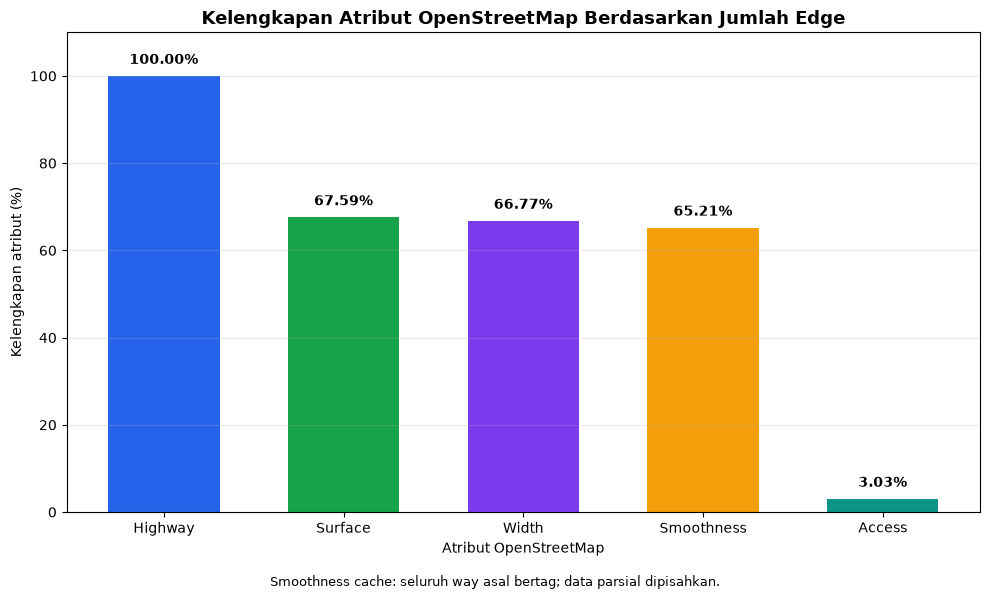

Diagram tersimpan di: /Users/david/widya_kartika/uwika-ta-31123022-2026/data_osm_5km/diagram_kelengkapan_atribut_osm.png


In [146]:
# ============================================================
# DIAGRAM KELENGKAPAN LIMA ATRIBUT OSM
# ============================================================
import matplotlib.pyplot as plt

# Gunakan angka dari tabel kelengkapan kelima atribut di atas.
attributes = attribute_completeness_df["atribut"].str.capitalize()
edge_completeness = attribute_completeness_df[
    "kelengkapan_berdasarkan_edge_persen"
]

fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = ["#2563EB", "#16A34A", "#7C3AED", "#F59E0B", "#0D9488"]
bars = ax.bar(attributes, edge_completeness, color=bar_colors, width=0.62)

ax.set_title(
    "Kelengkapan Atribut OpenStreetMap Berdasarkan Jumlah Edge",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Atribut OpenStreetMap")
ax.set_ylabel("Kelengkapan atribut (%)")
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20))
ax.grid(axis="y", alpha=0.25)

# Nilai persentase ditulis di atas batang agar gambar tetap informatif
# saat dipindahkan ke BAB IV tanpa tabel pendamping.
for bar, value in zip(bars, edge_completeness):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

fig.text(.5, .015, "Smoothness cache: seluruh way asal bertag; data parsial dipisahkan.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, .04, 1, 1])

# Simpan gambar resolusi tinggi sebagai kandidat gambar BAB IV.
completeness_diagram_path = DATA_DIR / "diagram_kelengkapan_atribut_osm.png"
fig.savefig(completeness_diagram_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"Diagram tersimpan di: {completeness_diagram_path.resolve()}")


### Distribusi Jenis Jalan (`highway`)

Bagian ini menampilkan distribusi jenis jalan pada edge graf berdasarkan jumlah edge dan total panjang edge directed.  
Analisis digunakan untuk memahami komposisi jaringan jalan yang menjadi ruang aksi agen serta menjadi dasar penyusunan skor kenyamanan berdasarkan jenis jalan.

In [147]:
# ============================================================
# DISTRIBUSI JENIS JALAN BERDASARKAN ATRIBUT HIGHWAY
# ============================================================

# Buat salinan tabel edge agar kolom analisis baru tidak mengubah data asli.
highway_analysis = edges_table.copy()

# Setelah simplify=True, sebagian kecil edge dapat memiliki lebih dari satu
# nilai highway. Nilai tersebut diubah menjadi teks agar tetap dapat dihitung
# sebagai satu edge dan panjangnya tidak terduplikasi.
highway_analysis["highway_label"] = (
    highway_analysis["highway"]
    .apply(lambda value: str(value) if isinstance(value, (list, tuple, set)) else value)
    .fillna("tidak_terisi")
    .astype(str)
)

# Kelompokkan edge berdasarkan jenis highway.
# total_panjang_edge_m tetap menghitung setiap edge satu kali.
highway_distribution_df = (
    highway_analysis
    .groupby("highway_label", as_index=False)
    .agg(
        jumlah_edge=("highway_label", "size"),
        total_panjang_edge_m=("length", "sum"),
        rata_rata_panjang_edge_m=("length", "mean"),
    )
)

# Hitung persentase jumlah edge dan persentase panjang edge.
total_edge_count = highway_distribution_df["jumlah_edge"].sum()
total_edge_length_m = highway_distribution_df["total_panjang_edge_m"].sum()

highway_distribution_df["persentase_edge"] = (
    highway_distribution_df["jumlah_edge"] / total_edge_count * 100
)

highway_distribution_df["persentase_panjang_edge"] = (
    highway_distribution_df["total_panjang_edge_m"] / total_edge_length_m * 100
)

# Urutkan dari jenis jalan dengan total panjang terbesar.
highway_distribution_df = (
    highway_distribution_df
    .sort_values("total_panjang_edge_m", ascending=False)
    .reset_index(drop=True)
)

print("=== DISTRIBUSI JENIS JALAN (HIGHWAY) ===")
display(
    highway_distribution_df.round(
        {
            "total_panjang_edge_m": 2,
            "rata_rata_panjang_edge_m": 2,
            "persentase_edge": 2,
            "persentase_panjang_edge": 2,
        }
    )
)

=== DISTRIBUSI JENIS JALAN (HIGHWAY) ===


,highway_label,jumlah_edge,total_panjang_edge_m,rata_rata_panjang_edge_m,persentase_edge,persentase_panjang_edge
0,residential,9208,619345.04,67.26,43.08,45.75
1,living_street,4640,305721.58,65.89,21.71,22.58
2,service,2390,116878.69,48.90,11.18,8.63
3,tertiary,1648,101797.58,61.77,7.71,7.52
4,secondary,1318,77910.14,59.11,6.17,5.75
5,primary,844,54160.88,64.17,3.95,4.00
6,trunk,386,24541.22,63.58,1.81,1.81
7,path,230,11455.79,49.81,1.08,0.85
8,"['living_street', 'residential']",88,11314.86,128.58,0.41,0.84
9,footway,232,9828.14,42.36,1.09,0.73


### Distribusi Jenis Permukaan Jalan (`surface`)

Bagian ini menampilkan distribusi nilai atribut `surface` pada edge graf, termasuk edge yang belum memiliki data permukaan.  
Analisis digunakan untuk mengetahui jenis permukaan yang tersedia sebagai indikator kenyamanan rute lari dan menentukan penanganan nilai `surface` yang kosong.

In [148]:
# ============================================================
# DISTRIBUSI JENIS PERMUKAAN JALAN BERDASARKAN ATRIBUT SURFACE
# ============================================================

# Buat salinan tabel edge agar analisis tidak mengubah data asli.
surface_analysis = edges_table.copy()


def surface_to_label(value):
    """
    Mengubah nilai surface menjadi label teks yang dapat dikelompokkan.

    - Nilai kosong diberi label 'tidak_terisi'.
    - Nilai list dari hasil simplify=True ditampilkan apa adanya sebagai
      kombinasi permukaan agar panjang edge tidak dihitung berulang.
    """
    if not has_osm_value(value):
        return "tidak_terisi"

    if isinstance(value, (list, tuple, set)):
        return str(list(value))

    return str(value).strip().lower()


# Buat kolom kategori surface yang siap untuk groupby.
surface_analysis["surface_label"] = surface_analysis["surface"].apply(
    surface_to_label
)

# Kelompokkan setiap edge berdasarkan nilai surface.
# Setiap edge dihitung sekali sehingga total panjang tidak terduplikasi.
surface_distribution_df = (
    surface_analysis
    .groupby("surface_label", as_index=False)
    .agg(
        jumlah_edge=("surface_label", "size"),
        total_panjang_edge_m=("length", "sum"),
        rata_rata_panjang_edge_m=("length", "mean"),
    )
)

# Hitung persentase berdasarkan jumlah edge dan total panjang edge.
total_edge_count = surface_distribution_df["jumlah_edge"].sum()
total_edge_length_m = surface_distribution_df["total_panjang_edge_m"].sum()

surface_distribution_df["persentase_edge"] = (
    surface_distribution_df["jumlah_edge"] / total_edge_count * 100
)

surface_distribution_df["persentase_panjang_edge"] = (
    surface_distribution_df["total_panjang_edge_m"] / total_edge_length_m * 100
)

# Urutkan dari panjang edge terbesar agar kategori dominan terlihat lebih dulu.
surface_distribution_df = (
    surface_distribution_df
    .sort_values("total_panjang_edge_m", ascending=False)
    .reset_index(drop=True)
)

print("=== DISTRIBUSI JENIS PERMUKAAN JALAN (SURFACE) ===")
display(
    surface_distribution_df.round(
        {
            "total_panjang_edge_m": 2,
            "rata_rata_panjang_edge_m": 2,
            "persentase_edge": 2,
            "persentase_panjang_edge": 2,
        }
    )
)

=== DISTRIBUSI JENIS PERMUKAAN JALAN (SURFACE) ===


,surface_label,jumlah_edge,total_panjang_edge_m,rata_rata_panjang_edge_m,persentase_edge,persentase_panjang_edge
0,paving_stones,7562,546048.54,72.21,35.38,40.33
1,asphalt,6446,395263.09,61.32,30.16,29.19
2,tidak_terisi,6928,375316.93,54.17,32.41,27.72
3,concrete,326,26523.48,81.36,1.53,1.96
4,"['paving_stones', 'asphalt']",30,2579.45,85.98,0.14,0.19
5,"['paving_stones', 'concrete']",18,2462.59,136.81,0.08,0.18
6,ground,24,2210.30,92.10,0.11,0.16
7,gravel,12,772.64,64.39,0.06,0.06
8,paved,6,661.49,110.25,0.03,0.05
9,"['unpaved', 'ground']",2,640.34,320.17,0.01,0.05


### Kualitas dan Distribusi Lebar Jalan (`width`)

Bagian ini memeriksa apakah nilai atribut `width` pada edge dapat dikonversi menjadi meter.  
Analisis dilakukan sebelum `width` digunakan sebagai indikator kenyamanan, karena nilai OSM dapat berupa angka, teks, nilai kosong, atau beberapa nilai yang digabungkan setelah proses simplifikasi graf.

In [149]:
# ============================================================
# ANALISIS KUALITAS DAN DISTRIBUSI ATRIBUT WIDTH
# ============================================================

import re

# Buat salinan tabel edge agar hasil parsing tidak mengubah data asli.
width_analysis = edges_table.copy()


def parse_width_to_meter(value):
    """
    Mengubah nilai width OSM menjadi meter secara konservatif.

    Status:
    - missing         : nilai width kosong.
    - parsed          : angka tunggal berhasil dikonversi ke meter.
    - multiple_values : ada list atau pemisah ';', sehingga tidak dipilih
                        salah satu nilainya secara sembarang.
    - invalid         : nilai ada, tetapi bukan angka lebar yang valid.
    """
    # Tangani nilai kosong lebih dahulu.
    if not has_osm_value(value):
        return np.nan, "missing"

    # Setelah simplify=True, width dapat menjadi list beberapa nilai.
    # Nilai seperti ini tidak langsung dipakai agar tidak salah interpretasi.
    if isinstance(value, (list, tuple, set)):
        return np.nan, "multiple_values"

    # Ubah menjadi teks kecil dan seragam.
    text = str(value).strip().lower().replace(",", ".")

    # Tanda ';' menunjukkan lebih dari satu nilai, misalnya "3;4".
    if ";" in text:
        return np.nan, "multiple_values"

    # Terima angka tunggal, dengan atau tanpa satuan m/meter/metre.
    match = re.fullmatch(
        r"(\d+(?:\.\d+)?)\s*(?:m|meter|metre|meters|metres)?",
        text,
    )

    if match is None:
        return np.nan, "invalid"

    width_m = float(match.group(1))

    # Lebar nol atau negatif tidak logis untuk ruas jalan.
    if width_m <= 0:
        return np.nan, "invalid"

    return width_m, "parsed"


# Terapkan parser ke seluruh nilai width.
width_parsed = width_analysis["width"].apply(parse_width_to_meter)

# Pisahkan hasil parser menjadi nilai meter dan status kualitas data.
width_analysis["width_meter"] = width_parsed.apply(lambda result: result[0])
width_analysis["width_parse_status"] = width_parsed.apply(lambda result: result[1])

# ------------------------------------------------------------
# 1. RINGKASAN KUALITAS NILAI WIDTH
# ------------------------------------------------------------
width_quality_df = (
    width_analysis
    .groupby("width_parse_status", as_index=False)
    .agg(
        jumlah_edge=("width_parse_status", "size"),
        total_panjang_edge_m=("length", "sum"),
    )
)

# Hitung persentase berdasarkan jumlah edge dan panjang edge.
width_quality_df["persentase_edge"] = (
    width_quality_df["jumlah_edge"] / len(width_analysis) * 100
)

width_quality_df["persentase_panjang_edge"] = (
    width_quality_df["total_panjang_edge_m"] / width_analysis["length"].sum() * 100
)

# Urutkan status agar mudah dibaca.
status_order = ["parsed", "missing", "multiple_values", "invalid"]
width_quality_df["urutan_status"] = width_quality_df["width_parse_status"].map(
    {status: index for index, status in enumerate(status_order)}
)

width_quality_df = (
    width_quality_df
    .sort_values("urutan_status")
    .drop(columns="urutan_status")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. STATISTIK WIDTH YANG BERHASIL DIPARSE
# ------------------------------------------------------------
valid_width_m = width_analysis.loc[
    width_analysis["width_parse_status"] == "parsed",
    "width_meter",
]

width_statistics_df = pd.DataFrame(
    {
        "statistik": [
            "jumlah_edge_width_valid",
            "minimum_m",
            "rata_rata_m",
            "median_m",
            "maksimum_m",
            "simpangan_baku_m",
        ],
        "nilai": [
            len(valid_width_m),
            valid_width_m.min(),
            valid_width_m.mean(),
            valid_width_m.median(),
            valid_width_m.max(),
            valid_width_m.std(),
        ],
    }
)

# ------------------------------------------------------------
# 3. CONTOH NILAI WIDTH MENTAH YANG PALING SERING MUNCUL
# ------------------------------------------------------------
# Bagian ini membantu melihat format asli data sebelum dipakai pada reward.
width_raw_distribution_df = (
    width_analysis
    .assign(width_raw_label=width_analysis["width"].fillna("tidak_terisi").astype(str))
    .groupby("width_raw_label", as_index=False)
    .agg(
        jumlah_edge=("width_raw_label", "size"),
        total_panjang_edge_m=("length", "sum"),
    )
    .sort_values("jumlah_edge", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

print("=== KUALITAS NILAI WIDTH ===")
display(
    width_quality_df.round(
        {
            "total_panjang_edge_m": 2,
            "persentase_edge": 2,
            "persentase_panjang_edge": 2,
        }
    )
)

print("=== STATISTIK WIDTH YANG BERHASIL DIPARSE (METER) ===")
display(width_statistics_df.round(2))

print("=== 20 NILAI WIDTH MENTAH PALING SERING MUNCUL ===")
display(width_raw_distribution_df.round({"total_panjang_edge_m": 2}))

=== KUALITAS NILAI WIDTH ===


,width_parse_status,jumlah_edge,total_panjang_edge_m,persentase_edge,persentase_panjang_edge
0,parsed,14146,948381.53,66.18,70.05
1,missing,7102,388217.46,33.23,28.67
2,multiple_values,126,17290.15,0.59,1.28


=== STATISTIK WIDTH YANG BERHASIL DIPARSE (METER) ===


,statistik,nilai
0,jumlah_edge_width_valid,14146.00
1,minimum_m,1.00
2,rata_rata_m,3.53
3,median_m,3.00
4,maksimum_m,20.00
5,simpangan_baku_m,1.89


=== 20 NILAI WIDTH MENTAH PALING SERING MUNCUL ===


,width_raw_label,jumlah_edge,total_panjang_edge_m
0,tidak_terisi,7102,388217.46
1,3,3784,259559.56
2,4,3394,232734.41
3,2,3062,205178.77
4,6,1238,74269.17
5,1,596,37440.43
6,5,470,36520.93
7,2.5,428,30926.19
8,1.5,324,23500.30
9,8,320,16555.08


### Distribusi Kondisi Permukaan Jalan (`smoothness`)

Distribusi memakai tabel edge analisis yang sama dengan highway/surface/width:
satu edge dihitung sekali, termasuk bila nilainya berupa gabungan. Panjang dan
persentase menggunakan seluruh edge directed sebagai pembagi. Nilai parsial dari
way asal belum digunakan sebagai nilai seluruh edge; cakupannya ditampilkan terpisah.

Smoothness mengacu pada keteraturan permukaan untuk kendaraan beroda, bukan
survei pelari. Nilai tidak dikenal tetap ditampilkan dan belum diberi skor.
[Dokumentasi smoothness](https://wiki.openstreetmap.org/wiki/Key:smoothness).

In [150]:
smoothness_analysis = edges_table.copy()
smoothness_analysis["smoothness_label"] = smoothness_analysis["smoothness"].apply(surface_to_label)
smoothness_distribution_df = (
    smoothness_analysis.groupby("smoothness_label", as_index=False)
    .agg(jumlah_edge=("smoothness_label", "size"), total_panjang_edge_m=("length", "sum"))
    .sort_values("total_panjang_edge_m", ascending=False).reset_index(drop=True))
smoothness_distribution_df["persentase_edge"] = smoothness_distribution_df["jumlah_edge"] / len(edges_table) * 100
smoothness_distribution_df["persentase_panjang_edge"] = (
    smoothness_distribution_df["total_panjang_edge_m"] / edges_table["length"].sum() * 100)
print("=== DISTRIBUSI SMOOTHNESS PADA EDGE ANALISIS ===")
display(smoothness_distribution_df.round(2))

smoothness_source_quality_df = (
    edges_table.groupby("smoothness_status", as_index=False)
    .agg(jumlah_edge=("length", "size"), total_panjang_edge_m=("length", "sum")))
print("=== CAKUPAN DATA SMOOTHNESS ===")
display(smoothness_source_quality_df.round(2))
known_smoothness = {"excellent", "good", "intermediate", "bad", "very_bad",
                    "horrible", "very_horrible", "impassable"}
smoothness_unknown_df = smoothness_analysis.loc[
    smoothness_analysis["smoothness"].apply(
        lambda value: any(v not in known_smoothness for v in osm_values(value) if v))]
print("=== CONTOH NILAI SMOOTHNESS BELUM DIKENAL ===")
display(smoothness_unknown_df[["u", "v", "key", "osmid", "smoothness", "length"]].head(20))
print("=== CONTOH DATA PARSIAL / SUMBER BELUM LENGKAP ===")
display(edges_table.loc[edges_table["smoothness_status"].isin(
    ["cache_sebagian_way_bertag", "sumber_way_belum_lengkap"]),
    ["u", "v", "key", "osmid", "smoothness_nilai_asal", "smoothness_status"]].head(10))

=== DISTRIBUSI SMOOTHNESS PADA EDGE ANALISIS ===


,smoothness_label,jumlah_edge,total_panjang_edge_m,persentase_edge,persentase_panjang_edge
0,intermediate,10714,712339.59,50.13,52.61
1,tidak_terisi,7436,421847.34,34.79,31.16
2,good,2676,185301.17,12.52,13.69
3,bad,348,22895.18,1.63,1.69
4,excellent,142,7658.20,0.66,0.57
5,"['good', 'intermediate']",16,1553.79,0.07,0.11
6,"['bad', 'intermediate']",14,1227.24,0.07,0.09
7,2,26,927.05,0.12,0.07
8,"['excellent', 'good']",2,139.60,0.01,0.01


=== CAKUPAN DATA SMOOTHNESS ===


,smoothness_status,jumlah_edge,total_panjang_edge_m
0,cache_sebagian_way_bertag,216,27348.71
1,cache_seluruh_way_bertag,13938,932041.81
2,tag_tidak_terisi,7220,394498.63


=== CONTOH NILAI SMOOTHNESS BELUM DIKENAL ===


,u,v,key,osmid,smoothness,length
4419,1720772126,5591588668,0,458638270,2,67.770936
4424,5591588668,4527536523,0,458638270,2,5.159927
4425,5591588668,1720772126,0,458638270,2,67.770936
4535,1720772221,4527536998,0,458638270,2,36.037922
4536,1720772221,4527536523,0,458638270,2,32.281609
4538,4527536998,4546075192,0,160014145,2,21.945323
4540,4527536998,1720772221,0,458638270,2,36.037922
4541,4527536523,1720772221,0,458638270,2,32.281609
4542,4527536523,5591588668,0,458638270,2,5.159927
4543,4527536523,4527537014,0,456494284,2,69.760867


=== CONTOH DATA PARSIAL / SUMBER BELUM LENGKAP ===


,u,v,key,osmid,smoothness_nilai_asal,smoothness_status
87,270613454,5591898087,0,"[585087314, 585087316]",[excellent],cache_sebagian_way_bertag
99,5591898087,270613454,0,"[585087314, 585087316]",[excellent],cache_sebagian_way_bertag
481,4520374458,4514942748,0,"[455032306, 455032298, 455032300]",[intermediate],cache_sebagian_way_bertag
527,421219497,421219495,0,"[36048880, 450298091, 450298092]",[good],cache_sebagian_way_bertag
554,311674231,5575280016,0,"[640991395, 1516177022]",[intermediate],cache_sebagian_way_bertag
563,5575280016,311674231,0,"[640991395, 1516177022]",[intermediate],cache_sebagian_way_bertag
613,5575519685,1720976331,1,"[160036155, 583154503]",[good],cache_sebagian_way_bertag
678,312079869,1720905988,0,"[1119980393, 160028871]",[intermediate],cache_sebagian_way_bertag
692,1720905988,312079869,0,"[1119980393, 160028871]",[intermediate],cache_sebagian_way_bertag
843,5587366951,9464948322,0,"[1053280155, 327728879]",[excellent],cache_sebagian_way_bertag


### Distribusi Akses Jalan (`access`)

Tabel utama memakai `access` pada **edge analisis yang sama dengan empat atribut lain**, termasuk data kosong dan
nilai gabungan. Tabel pendamping memeriksa `access` dan `foot` pada **way asal yang
sama**, karena `foot=yes` dapat menjadi pengecualian terhadap `access=no`.
Jangan menyimpulkan izin seluruh edge gabungan dari tag pada way yang berbeda.

Bagian ini hanya menampilkan data untuk ditinjau; belum menetapkan larangan,
penalti, atau perubahan action mask. Tag kosong tidak membuktikan akses publik.
[Dokumentasi access](https://wiki.openstreetmap.org/wiki/Key:access#Transport_mode_restrictions).

In [151]:
access_analysis = edges_table.copy()
if "access" not in access_analysis:
    access_analysis["access"] = None
access_analysis["access_label"] = access_analysis["access"].apply(surface_to_label)
access_distribution_df = (
    access_analysis.groupby("access_label", as_index=False)
    .agg(jumlah_edge=("access_label", "size"), total_panjang_edge_m=("length", "sum"))
    .sort_values("jumlah_edge", ascending=False).reset_index(drop=True))
access_distribution_df["persentase_edge"] = access_distribution_df["jumlah_edge"] / len(access_analysis) * 100
access_distribution_df["persentase_panjang_edge"] = (
    access_distribution_df["total_panjang_edge_m"] / access_analysis["length"].sum() * 100)
print("=== DISTRIBUSI ACCESS PADA EDGE GRAF ===")
display(access_distribution_df.round(2))

# Pemeriksaan pendamping untuk menafsirkan access; bukan analisis tag baru.
access_source_review_df = source_tags_df.loc[
    source_tags_df["access"].apply(surface_to_label).isin(["no", "private", "destination"]),
    ["osmid", "name", "access", "foot"],
].copy()
if source_tags_df.empty:
    print("Pemeriksaan access--foot pada way asal dilewati karena cache tidak tersedia/cocok.")
else:
    print("=== WAY ASAL DENGAN ACCESS NO/PRIVATE/DESTINATION DAN NILAI FOOT ===")
    display(access_source_review_df)

print("=== CONTOH EDGE DENGAN ACCESS TERISI ===")
sample_columns = [c for c in ["u", "v", "key", "osmid", "name", "access", "length"] if c in access_analysis]
display(access_analysis.loc[access_analysis["access_label"] != "tidak_terisi", sample_columns].head(20))

=== DISTRIBUSI ACCESS PADA EDGE GRAF ===


,access_label,jumlah_edge,total_panjang_edge_m,persentase_edge,persentase_panjang_edge
0,tidak_terisi,20726,1303889.92,96.97,96.31
1,permissive,390,32238.73,1.82,2.38
2,yes,184,11674.35,0.86,0.86
3,destination,50,3822.72,0.23,0.28
4,no,24,2263.43,0.11,0.17


=== WAY ASAL DENGAN ACCESS NO/PRIVATE/DESTINATION DAN NILAI FOOT ===


,osmid,name,access,foot
137,156488645,Jalan Simo Sidomulyo II,destination,NaN
174,156488767,Jalan Simo Sidomulyo VI,destination,NaN
229,156541827,Jalan Simo Sidomulyo X,destination,NaN
1023,160223681,Jalan Praban Wetan III,destination,NaN
3342,583075345,NaN,destination,NaN
3592,583621637,NaN,destination,NaN
3889,584814586,NaN,no,NaN
4384,753623143,Jalan Pakis Argosari VI,no,NaN
4392,754450972,Jalan Satelit Indah I,no,NaN
4400,754788896,Jalan Kupang Indah XIV,no,NaN


=== CONTOH EDGE DENGAN ACCESS TERISI ===


,u,v,key,osmid,name,access,length
42,6865508913,9157287517,0,583621637,NaN,destination,88.082879
45,6868863246,9157287517,0,991093854,NaN,destination,70.293169
87,270613454,5591898087,0,"[585087314, 585087316]",Jalan Kedungsari,yes,61.723614
99,5591898087,270613454,0,"[585087314, 585087316]",Jalan Kedungsari,yes,61.723614
100,5591898087,6829283784,0,852306993,Jalan Kedungsari,yes,280.423531
249,311432950,4514943336,0,"[954114176, 455679691, 455679684]",Jalan Wonokitri Besar,permissive,190.437175
301,311431252,4520228487,0,"[160013914, 847055678]",Jalan Putat Jaya Timur I B,permissive,43.913832
307,1720774711,5587512187,0,"[847055677, 160014111]",Jalan Putat Jaya Timur Tembusan B,permissive,67.154327
311,4520228487,5587512186,0,160013914,Jalan Putat Jaya Timur I B,permissive,56.052428
313,4520228487,311431252,0,"[160013914, 847055678]",Jalan Putat Jaya Timur I B,permissive,43.913832


## Diagram Distribusi Atribut Ruas Jalan

Diagram merangkum distribusi highway, surface, width, smoothness, dan access.
Highway, surface, smoothness, dan access menggunakan persentase total panjang
edge yang sama. Dua panel width mempertahankan pemisahan kualitas data dan
sebaran nilai width valid; panel terakhir ini hanya menggunakan edge width valid.
Smoothness parsial tetap dicatat terpisah dari nilai yang tersedia untuk seluruh edge.

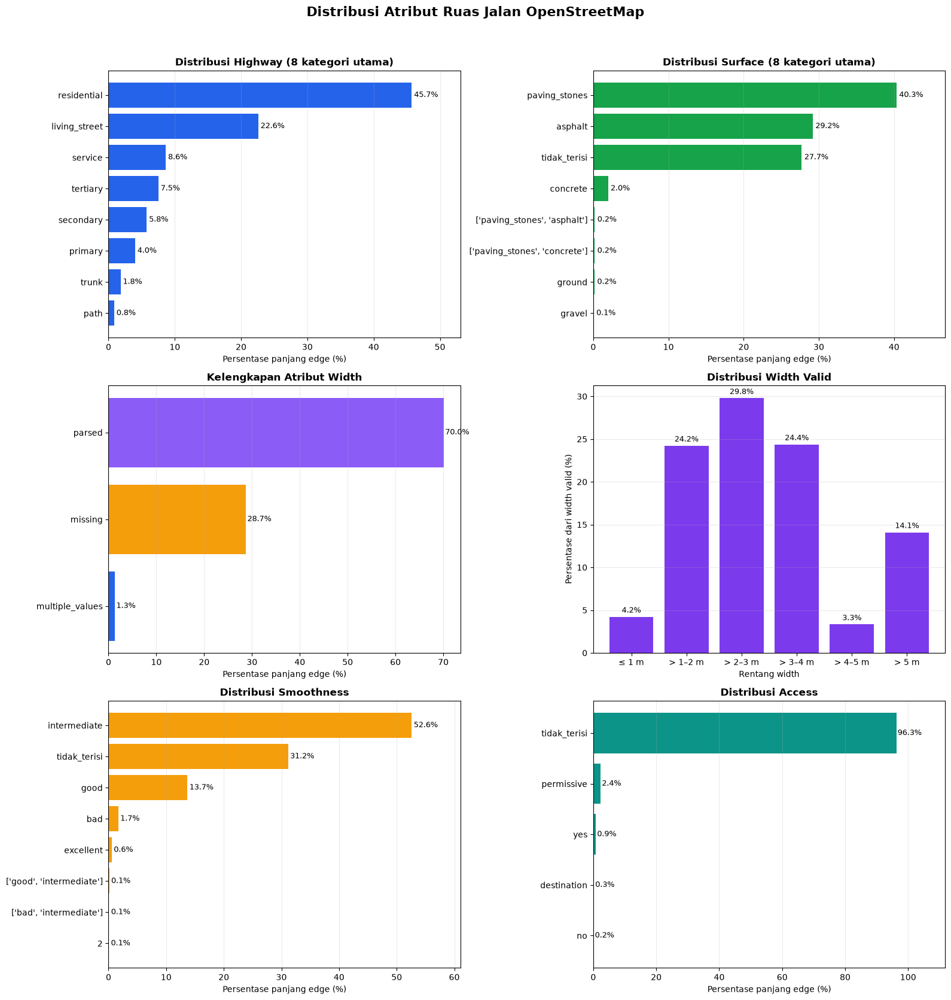

Diagram tersimpan di: /Users/david/widya_kartika/uwika-ta-31123022-2026/data_osm_5km/diagram_distribusi_atribut_osm.png


In [152]:
# ============================================================
# DIAGRAM DISTRIBUSI LIMA ATRIBUT RUAS JALAN
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Fungsi kecil agar diagram batang horizontal memiliki tampilan konsisten.
def plot_horizontal_percentage(ax, data, label_column, value_column, title, color):
    plot_data = data.copy().sort_values(value_column, ascending=True)
    ax.barh(plot_data[label_column], plot_data[value_column], color=color)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Persentase panjang edge (%)")
    ax.grid(axis="x", alpha=0.25)
    ax.set_xlim(0, max(float(plot_data[value_column].max()) * 1.16, 1))

    # Tulis nilai persentase pada ujung setiap batang.
    for y_pos, value in enumerate(plot_data[value_column]):
        ax.text(value + 0.35, y_pos, f"{value:.1f}%", va="center", fontsize=9)


# Ambil delapan kategori dengan panjang edge terbesar agar label tetap terbaca.
highway_top = highway_distribution_df.nlargest(8, "persentase_panjang_edge")
surface_top = surface_distribution_df.nlargest(8, "persentase_panjang_edge")

# Ringkas nilai width valid ke rentang meter agar distribusinya mudah dibaca.
width_bin_edges = [0, 1, 2, 3, 4, 5, np.inf]
width_bin_labels = ["≤ 1 m", "> 1–2 m", "> 2–3 m", "> 3–4 m", "> 4–5 m", "> 5 m"]
width_interval = pd.cut(
    valid_width_m,
    bins=width_bin_edges,
    labels=width_bin_labels,
    include_lowest=True,
)
width_value_distribution_df = (
    width_interval
    .value_counts(sort=False)
    .reindex(width_bin_labels, fill_value=0)
    .rename_axis("rentang_width")
    .reset_index(name="jumlah_edge")
)
width_value_distribution_df["persentase_width_valid"] = (
    width_value_distribution_df["jumlah_edge"] / len(valid_width_m) * 100
)

# Enam panel: empat distribusi kategori dan dua pemeriksaan width.
fig, axes = plt.subplots(3, 2, figsize=(16, 17))

plot_horizontal_percentage(
    axes[0, 0],
    highway_top,
    "highway_label",
    "persentase_panjang_edge",
    "Distribusi Highway (8 kategori utama)",
    "#2563EB",
)

plot_horizontal_percentage(
    axes[0, 1],
    surface_top,
    "surface_label",
    "persentase_panjang_edge",
    "Distribusi Surface (8 kategori utama)",
    "#16A34A",
)

# Kualitas width menunjukkan proporsi edge yang bisa digunakan langsung,
# kosong, atau memiliki lebih dari satu nilai yang tidak dipilih sembarang.
width_quality_plot = width_quality_df.sort_values("persentase_panjang_edge", ascending=True)
axes[1, 0].barh(
    width_quality_plot["width_parse_status"],
    width_quality_plot["persentase_panjang_edge"],
    color=["#2563EB", "#F59E0B", "#8B5CF6", "#DC2626"][:len(width_quality_plot)],
)
axes[1, 0].set_title("Kelengkapan Atribut Width", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Persentase panjang edge (%)")
axes[1, 0].grid(axis="x", alpha=0.25)
for y_pos, value in enumerate(width_quality_plot["persentase_panjang_edge"]):
    axes[1, 0].text(value + 0.35, y_pos, f"{value:.1f}%", va="center", fontsize=9)

# Distribusi berikut hanya memakai width yang telah berhasil dikonversi ke meter.
axes[1, 1].bar(
    width_value_distribution_df["rentang_width"],
    width_value_distribution_df["persentase_width_valid"],
    color="#7C3AED",
)
axes[1, 1].set_title("Distribusi Width Valid", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Rentang width")
axes[1, 1].set_ylabel("Persentase dari width valid (%)")
axes[1, 1].grid(axis="y", alpha=0.25)
for x_pos, value in enumerate(width_value_distribution_df["persentase_width_valid"]):
    axes[1, 1].text(x_pos, value + 0.5, f"{value:.1f}%", ha="center", fontsize=9)

# Gunakan tabel distribusi yang sama dengan bagian smoothness/access di atas.
plot_horizontal_percentage(
    axes[2, 0], smoothness_distribution_df.nlargest(8, "persentase_panjang_edge"),
    "smoothness_label", "persentase_panjang_edge", "Distribusi Smoothness", "#F59E0B")
plot_horizontal_percentage(
    axes[2, 1], access_distribution_df.nlargest(8, "persentase_panjang_edge"),
    "access_label", "persentase_panjang_edge", "Distribusi Access", "#0D9488")

fig.suptitle("Distribusi Atribut Ruas Jalan OpenStreetMap", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])

# Simpan PNG resolusi tinggi agar dapat dipakai sebagai calon gambar BAB IV.
diagram_path = DATA_DIR / "diagram_distribusi_atribut_osm.png"
fig.savefig(diagram_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"Diagram tersimpan di: {diagram_path.resolve()}")


### Distribusi Tujuan Node dan Jalan Buntu

Bagian ini menganalisis jumlah node tujuan unik yang dapat dicapai dari setiap node. Metrik ini adalah indikator struktur percabangan graf dan membantu mengidentifikasi node dengan pilihan perpindahan terbatas.

Pada training, action Q-table didefinisikan lebih rinci sebagai `(next_node, key)`. Karena itu, edge paralel menuju node tujuan yang sama tetap dibedakan bila memiliki `key` berbeda. Jumlah tujuan unik pada bagian ini tidak selalu sama dengan jumlah action final pada Q-table.

In [153]:
# ============================================================
# DISTRIBUSI TUJUAN NODE UNIK DAN JALAN BUNTU PADA GRAF
# ============================================================

action_rows = []

for node in G.nodes:
    # raw_out_degree menghitung semua edge keluar, termasuk edge paralel.
    raw_out_degree = G.out_degree(node)

    # unique_next_nodes menghitung node tujuan yang berbeda.
    # Metrik ini menghitung tujuan node yang berbeda sebagai indikator struktur graf.
    # Action Q-table pada training tetap membedakan edge dengan key yang berbeda.
    unique_next_nodes = len(set(G.successors(node)))

    action_rows.append(
        {
            "node": node,
            "raw_out_degree": raw_out_degree,
            "jumlah_tujuan_unik": unique_next_nodes,
            "street_count": G.nodes[node].get("street_count"),
        }
    )

# Buat tabel jumlah action untuk seluruh node.
node_action_df = pd.DataFrame(action_rows)

# Klasifikasikan node berdasarkan jumlah action yang tersedia.
def destination_category(destination_count):
    if destination_count == 0:
        return "0_tujuan_jalan_buntu"
    if destination_count == 1:
        return "1_tujuan_terpaksa"
    if destination_count == 2:
        return "2_tujuan"
    if destination_count == 3:
        return "3_tujuan"
    if destination_count == 4:
        return "4_tujuan"
    return "5_atau_lebih_tujuan"


node_action_df["kategori_tujuan"] = node_action_df[
    "jumlah_tujuan_unik"
].apply(destination_category)

# ------------------------------------------------------------
# 1. DISTRIBUSI JUMLAH TUJUAN UNIK PER NODE
# ------------------------------------------------------------
action_distribution_df = (
    node_action_df
    .groupby("jumlah_tujuan_unik", as_index=False)
    .agg(
        jumlah_node=("node", "size"),
        rata_rata_raw_out_degree=("raw_out_degree", "mean"),
    )
    .sort_values("jumlah_tujuan_unik")
    .reset_index(drop=True)
)

# Hitung persentase node pada setiap jumlah action.
action_distribution_df["persentase_node"] = (
    action_distribution_df["jumlah_node"] / len(node_action_df) * 100
)

# ------------------------------------------------------------
# 2. RINGKASAN NODE JALAN BUNTU DAN NODE TERPAKSA
# ------------------------------------------------------------
destination_category_summary_df = (
    node_action_df
    .groupby("kategori_tujuan", as_index=False)
    .agg(jumlah_node=("node", "size"))
)

# Urutan kategori dibuat agar hasil mudah dibaca.
category_order = [
    "0_tujuan_jalan_buntu",
    "1_tujuan_terpaksa",
    "2_tujuan",
    "3_tujuan",
    "4_tujuan",
    "5_atau_lebih_tujuan",
]

destination_category_summary_df["urutan"] = destination_category_summary_df[
    "kategori_tujuan"
].map({category: index for index, category in enumerate(category_order)})

destination_category_summary_df = (
    destination_category_summary_df
    .sort_values("urutan")
    .drop(columns="urutan")
    .reset_index(drop=True)
)

destination_category_summary_df["persentase_node"] = (
    destination_category_summary_df["jumlah_node"] / len(node_action_df) * 100
)

# ------------------------------------------------------------
# 3. INFORMASI ACTION PADA NODE START
# ------------------------------------------------------------
start_action_df = node_action_df[
    node_action_df["node"] == start_node
].copy()

print("=== DISTRIBUSI JUMLAH TUJUAN UNIK PER NODE ===")
display(action_distribution_df.round(2))

print("=== RINGKASAN JALAN BUNTU DAN NODE TERPAKSA ===")
display(destination_category_summary_df.round(2))

print("=== TUJUAN UNIK PADA NODE START ===")
display(start_action_df)

=== DISTRIBUSI JUMLAH TUJUAN UNIK PER NODE ===


,jumlah_tujuan_unik,jumlah_node,rata_rata_raw_out_degree,persentase_node
0,1,1709,1.00,21.29
1,2,252,2.73,3.14
2,3,5310,3.00,66.15
3,4,749,4.00,9.33
4,5,2,5.00,0.02
5,6,5,6.00,0.06


=== RINGKASAN JALAN BUNTU DAN NODE TERPAKSA ===


,kategori_tujuan,jumlah_node,persentase_node
0,1_tujuan_terpaksa,1709,21.29
1,2_tujuan,252,3.14
2,3_tujuan,5310,66.15
3,4_tujuan,749,9.33
4,5_atau_lebih_tujuan,7,0.09


=== TUJUAN UNIK PADA NODE START ===


,node,raw_out_degree,jumlah_tujuan_unik,street_count,kategori_tujuan
129,1720975931,3,3,3,3_tujuan


### Peta Interaktif Atribut Jalan dan Akses

Peta menampilkan jaringan jalan, titik awal, dan atribut ruas untuk inspeksi.
Saat dibuka, hanya warna ruas **Highway (jenis jalan)** dan marker START yang aktif.
Gunakan kontrol layer untuk memilih **Surface (permukaan jalan)** atau
**Smoothness**. Ketiga tema warna ruas ditampilkan bergantian; basemap tetap aktif.

Warna Surface membedakan material asli, misalnya paving_stones, asphalt, dan
concrete, serta kategori gabungan, nilai lainnya, dan tag kosong. Tooltip
menampilkan nilai surface asli dan skor dari core: prioritas +1
(asphalt/concrete/paving_stones/paved), lainnya -1, kosong 0. Gabungan
menggunakan skor minimum. Warna material bukan tingkat keamanan atau kondisi
kerusakan jalan. Legenda mengikuti tema yang sedang dipilih.

Warna Smoothness mengikuti kategori data; nilai gabungan, tidak dikenal,
kosong, parsial, dan sumber belum lengkap dibedakan. Smoothness masih hanya
untuk analisis, belum menjadi komponen reward.

Marker **access** tersedia per jenis dan awalnya tidak aktif. Centang jenis
yang ingin diperiksa, lalu klik marker untuk melihat rincian ruas dan edge.
Marker berada di tengah ruas; edge dua arah identik berbagi satu marker,
sedangkan key paralel berbeda tetap terpisah. Marker bukan lokasi pasti pagar.
Peta memuat seluruh graf; sebagian ruas dapat dikeluarkan dari action training
oleh whitelist akses. Titik awal eksperimen tetap.


In [154]:
# ============================================================
# PETA INTERAKTIF ATRIBUT JALAN DAN AKSES
# ============================================================

import folium
import geopandas as gpd
from shapely.geometry import Point
from branca.element import MacroElement, Template
import importlib
import rute_lari_core as surface_core

# Muat aturan terbaru ketika cell ini dijalankan ulang pada kernel yang sama.
importlib.reload(surface_core)

# Warna untuk kategori highway yang dominan pada data penelitian.
HIGHWAY_COLORS = {
    "residential": "#2563EB",      # Biru
    "living_street": "#16A34A",    # Hijau
    "service": "#6B7280",          # Abu-abu
    "secondary": "#F97316",        # Oranye
    "tertiary": "#EAB308",         # Kuning
    "primary": "#DC2626",          # Merah
    "trunk": "#7C3AED",            # Ungu
    "footway": "#DB2777",          # Merah muda
    "path": "#14B8A6",             # Toska
    "unclassified": "#92400E",     # Cokelat
    "track": "#65A30D",            # Hijau zaitun
}

# Warna default untuk highway yang tidak tercantum pada kamus di atas.
DEFAULT_HIGHWAY_COLOR = "#9CA3AF"


def highway_for_map(value):
    """
    Mengubah nilai highway menjadi satu label peta.

    Jika edge hasil simplify memiliki lebih dari satu highway,
    labelnya dibuat 'gabungan' dan memakai warna default.
    """
    if isinstance(value, (list, tuple, set)):
        return "gabungan"

    if not has_osm_value(value):
        return "tidak_terisi"

    return str(value).strip().lower()


# Ubah edge dari CRS meter ke WGS84 agar kompatibel dengan Folium.
# Folium membutuhkan koordinat latitude-longitude.
edges_map = edges_gdf.to_crs(epsg=4326).reset_index().copy()

# Buat label kategori dan warna untuk setiap edge.
edges_map["highway_map_label"] = edges_map["highway"].apply(highway_for_map)
edges_map["color"] = edges_map["highway_map_label"].map(HIGHWAY_COLORS)
edges_map["color"] = edges_map["color"].fillna(DEFAULT_HIGHWAY_COLOR)

# Warna material asli dipisahkan dari kelompok skor agar inspeksi tetap rinci.
SURFACE_COLORS = {
    "asphalt": "#2563EB", "concrete": "#F97316", "paving_stones": "#16A34A",
    "paved": "#06B6D4", "sett": "#D97706", "compacted": "#84CC16",
    "fine_gravel": "#EAB308", "gravel": "#92400E", "dirt": "#DC2626",
    "ground": "#A16207", "unpaved": "#7C3AED",
    "gabungan_kategori": "#DB2777", "nilai_lainnya": "#475569",
    "tidak_terisi": "#9CA3AF",
}

def surface_for_map(value):
    values = sorted({part.strip() for item in surface_core.osm_values(value)
                     for part in item.split(";") if part.strip()})
    if not values:
        return "tidak_terisi"
    if len(values) > 1:
        return "gabungan_kategori"
    return values[0] if values[0] in SURFACE_COLORS else "nilai_lainnya"

edges_map["surface_map_label"] = edges_map["surface"].apply(surface_for_map)
edges_map["surface_color"] = edges_map["surface_map_label"].map(SURFACE_COLORS)
edges_map["surface_score_map"] = edges_map["surface"].apply(surface_core.calculate_surface_score)

# Kategori hanya untuk warna peta; tidak menghitung atau mengubah skor reward.
SMOOTHNESS_COLORS = {
    "excellent": "#15803D", "good": "#22C55E", "intermediate": "#EAB308",
    "bad": "#F97316", "very_bad": "#DC2626", "horrible": "#991B1B",
    "very_horrible": "#7F1D1D", "impassable": "#4C1D95",
    "gabungan_kategori": "#2563EB", "nilai_tidak_dikenal": "#A855F7",
    "data_parsial": "#6366F1", "sumber_belum_lengkap": "#64748B",
    "tidak_terisi": "#9CA3AF",
}

def smoothness_for_map(value, status):
    if status == "cache_sebagian_way_bertag":
        return "data_parsial"
    if status == "sumber_way_belum_lengkap":
        return "sumber_belum_lengkap"
    values = sorted({item for item in osm_values(value) if item})
    if not values:
        return "tidak_terisi"
    known = {"excellent", "good", "intermediate", "bad", "very_bad",
             "horrible", "very_horrible", "impassable"}
    if not set(values).issubset(known):
        return "nilai_tidak_dikenal"
    return values[0] if len(values) == 1 else "gabungan_kategori"

edges_map["smoothness_map_label"] = [
    smoothness_for_map(value, status)
    for value, status in zip(edges_map["smoothness"], edges_map["smoothness_status"])]
edges_map["smoothness_color"] = edges_map["smoothness_map_label"].map(SMOOTHNESS_COLORS)

# Bulatkan panjang edge agar tooltip lebih mudah dibaca.
edges_map["length_m"] = edges_map["length"].round(1)

# Ubah koordinat node start dari CRS meter ke WGS84.
start_point_projected = Point(
    G.nodes[start_node]["x"],
    G.nodes[start_node]["y"],
)

start_point_wgs84 = (
    gpd.GeoSeries([start_point_projected], crs=G.graph["crs"])
    .to_crs(epsg=4326)
    .iloc[0]
)

# Tooltip memakai tabel atribut yang sama dengan kelengkapan/distribusi.
for attribute in ["surface", "width", "smoothness", "access", "smoothness_status"]:
    edges_map[f"{attribute}_display"] = edges_map[attribute].apply(surface_to_label)

# Buat peta dengan basemap OpenStreetMap.
graph_map = folium.Map(
    location=[start_point_wgs84.y, start_point_wgs84.x],
    zoom_start=14,
    tiles=None,
    control_scale=True,
)

# Basemap selalu tampil, sedangkan tiga tema warna ruas dipilih bergantian.
folium.TileLayer("OpenStreetMap", control=False).add_to(graph_map)
highway_layer = folium.FeatureGroup(
    name="Highway (jenis jalan)", overlay=False, show=True).add_to(graph_map)
surface_layer = folium.FeatureGroup(
    name="Surface (permukaan jalan)", overlay=False, show=False).add_to(graph_map)
smoothness_layer = folium.FeatureGroup(
    name="Smoothness", overlay=False, show=False).add_to(graph_map)

# Tambahkan seluruh edge sebagai satu layer GeoJSON agar lebih efisien
# dibandingkan menambahkan satu PolyLine untuk setiap edge.
folium.GeoJson(
    data=edges_map[
        ["u", "v", "key", "highway_map_label", "surface_display", "width_display", "smoothness_display", "access_display", "smoothness_status_display", "length_m", "color", "geometry"]
    ].to_json(),
    style_function=lambda feature: {
        "color": feature["properties"]["color"],
        "weight": 2.5,
        "opacity": 0.75,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["highway_map_label", "surface_display", "width_display", "smoothness_display", "access_display", "smoothness_status_display", "length_m"],
        aliases=["Jenis jalan", "Surface", "Width", "Smoothness", "Access", "Sumber/cakupan smoothness", "Panjang edge (m)"],
        localize=True,
        sticky=False,
    ),
    name="Highway", control=False,
).add_to(highway_layer)

# Surface mempertahankan kategori material; skor tooltip memakai core bersama.
folium.GeoJson(
    data=edges_map[["u", "v", "key", "highway_map_label", "surface_map_label",
        "surface_display", "surface_score_map", "width_display", "smoothness_display",
        "access_display", "smoothness_status_display", "length_m", "surface_color", "geometry"]].to_json(),
    style_function=lambda feature: {
        "color": feature["properties"]["surface_color"], "weight": 2.5, "opacity": .85},
    tooltip=folium.GeoJsonTooltip(
        fields=["surface_display", "surface_map_label", "surface_score_map", "highway_map_label",
                "width_display", "smoothness_display", "access_display", "smoothness_status_display", "length_m"],
        aliases=["Surface asli", "Kategori warna", "Skor surface", "Jenis jalan",
                 "Width", "Smoothness", "Access", "Sumber/cakupan smoothness", "Panjang edge (m)"],
        localize=True, sticky=False),
    name="Surface", control=False,
).add_to(surface_layer)

# Geometri dan atribut tetap sama; hanya warna ruas yang berganti.
folium.GeoJson(
    data=edges_map[["u", "v", "key", "highway_map_label", "smoothness_map_label",
        "surface_display", "width_display", "smoothness_display", "access_display",
        "smoothness_status_display", "length_m", "smoothness_color", "geometry"]].to_json(),
    style_function=lambda feature: {
        "color": feature["properties"]["smoothness_color"], "weight": 2.5, "opacity": .85},
    tooltip=folium.GeoJsonTooltip(
        fields=["highway_map_label", "surface_display", "width_display", "smoothness_display",
                "smoothness_map_label", "access_display", "smoothness_status_display", "length_m"],
        aliases=["Jenis jalan", "Surface", "Width", "Smoothness", "Kategori warna",
                 "Access", "Sumber/cakupan smoothness", "Panjang edge (m)"],
        localize=True, sticky=False),
    name="Smoothness", control=False,
).add_to(smoothness_layer)

# Tambahkan marker titik start agen.
folium.Marker(
    location=[start_point_wgs84.y, start_point_wgs84.x],
    tooltip="START — node awal agen",
    popup=folium.Popup(
        f"<b>START</b><br>Node: {start_node}<br>"
        f"Jumlah tujuan unik: {int(start_action_df['jumlah_tujuan_unik'].iloc[0])}",
        max_width=250,
    ),
    icon=folium.Icon(color="green", icon="play", prefix="fa"),
).add_to(graph_map)

# Buat legenda warna highway.
legend_rows = "".join(
    f'<div style="margin:3px 0;">'
    f'<span style="display:inline-block;width:18px;height:5px;'
    f'background:{color};margin-right:6px;"></span>{highway}'
    f"</div>"
    for highway, color in HIGHWAY_COLORS.items()
)

highway_legend_id = f"highway_legend_{graph_map.get_name()}"
legend_html = f"""
<div id="{highway_legend_id}" style="
    position: fixed;
    left: 12px;
    bottom: 12px;
    z-index: 9999;
    background: rgba(255, 255, 255, 0.94);
    border: 1px solid #999;
    border-radius: 6px;
    padding: 8px 10px;
    font: 12px Arial, sans-serif;
    box-shadow: 0 1px 4px rgba(0, 0, 0, 0.25);
">
    <b>Jenis Jalan</b>
    {legend_rows}
</div>
"""

graph_map.get_root().html.add_child(folium.Element(legend_html))

# Legenda material Surface hanya muncul ketika tema Surface dipilih.
surface_legend_id = f"surface_legend_{graph_map.get_name()}"
surface_labels = {
    "gabungan_kategori": "Gabungan material (lihat tooltip)",
    "nilai_lainnya": "Material lainnya", "tidak_terisi": "Tidak terisi",
}
observed_surface = set(edges_map["surface_map_label"])
surface_legend_rows = "".join(
    f'<div style="margin:3px 0;"><span style="display:inline-block;width:18px;height:5px;'
    f'background:{color};margin-right:6px;"></span>{surface_labels.get(label, label)}</div>'
    for label, color in SURFACE_COLORS.items() if label in observed_surface)
surface_legend_html = (
    f'<div id="{surface_legend_id}" style="display:none;position:fixed;left:12px;bottom:12px;'
    'z-index:9999;background:rgba(255,255,255,.94);border:1px solid #999;'
    'border-radius:6px;padding:8px 10px;font:12px Arial,sans-serif;">'
    '<b>Surface (material permukaan)</b>' + surface_legend_rows + '</div>')
graph_map.get_root().html.add_child(folium.Element(surface_legend_html))

# Legenda smoothness awalnya disembunyikan dan mengikuti layer yang dipilih.
smoothness_legend_id = f"smoothness_legend_{graph_map.get_name()}"
smoothness_labels = {
    "gabungan_kategori": "Gabungan kategori (lihat tooltip)",
    "nilai_tidak_dikenal": "Nilai tidak dikenal", "data_parsial": "Data parsial",
    "sumber_belum_lengkap": "Sumber belum lengkap", "tidak_terisi": "Tidak terisi",
}
observed_smoothness = set(edges_map["smoothness_map_label"])
smoothness_legend_rows = "".join(
    f'<div style="margin:3px 0;"><span style="display:inline-block;width:18px;height:5px;'
    f'background:{color};margin-right:6px;"></span>{smoothness_labels.get(label, label)}</div>'
    for label, color in SMOOTHNESS_COLORS.items() if label in observed_smoothness)
smoothness_legend_html = (
    f'<div id="{smoothness_legend_id}" style="display:none;position:fixed;left:12px;bottom:12px;'
    'z-index:9999;background:rgba(255,255,255,.94);border:1px solid #999;'
    'border-radius:6px;padding:8px 10px;font:12px Arial,sans-serif;">'
    '<b>Smoothness</b>' + smoothness_legend_rows + '</div>')
graph_map.get_root().html.add_child(folium.Element(smoothness_legend_html))

# Marker access berada di tengah geometri ruas, dihitung pada CRS meter.
# Warna adalah kategori tag access; bukan hasil keputusan izin pejalan kaki.
from html import escape as html_escape

ACCESS_MARKER_STYLES = {
    "no": {"color": "red", "icon": "ban"},
    "private": {"color": "darkred", "icon": "lock"},
    "destination": {"color": "orange", "icon": "flag"},
    "permissive": {"color": "blue", "icon": "info-circle"},
    "yes": {"color": "green", "icon": "check"},
}
ACCESS_MARKER_DEFAULT = {"color": "purple", "icon": "question"}
access_marker_groups = {}
access_edges = edges_gdf.reset_index()
access_edges = access_edges.loc[access_edges["access"].apply(has_osm_value)].copy()
for row in access_edges.itertuples(index=False):
    geometry = row.geometry
    if geometry is None or geometry.is_empty:
        continue
    access_label = surface_to_label(row.access)
    # Gabungkan hanya representasi dua arah yang identik. Key paralel berbeda
    # tetap dipertahankan, dan seluruh identitas edge dicatat pada popup.
    signature = (
        tuple(sorted([int(row.u), int(row.v)])), int(row.key),
        geometry.normalize().wkb_hex, tuple(sorted(osm_values(row.osmid))), access_label,
    )
    if signature not in access_marker_groups:
        access_marker_groups[signature] = {
            "access": access_label,
            "name": str(row.name) if has_osm_value(row.name) else "tidak_terisi",
            "osmid": str(row.osmid), "highway": surface_to_label(row.highway),
            "length_m": float(row.length),
            "midpoint": geometry.interpolate(0.5, normalized=True),
            "edges": [],
        }
    access_marker_groups[signature]["edges"].append((int(row.u), int(row.v), int(row.key)))

access_marker_layers = {}
access_marker_counts = []
if access_marker_groups:
    access_midpoints = gpd.GeoSeries(
        [record["midpoint"] for record in access_marker_groups.values()],
        crs=edges_gdf.crs,
    ).to_crs(epsg=4326)
    for record, point in zip(access_marker_groups.values(), access_midpoints):
        label = record["access"]
        style = ACCESS_MARKER_STYLES.get(label, ACCESS_MARKER_DEFAULT)
        if label not in access_marker_layers:
            access_marker_layers[label] = folium.FeatureGroup(
                name=f"Marker access={label}", show=False).add_to(graph_map)
        edge_details = "<br>".join(
            f"{u} → {v} (key={key})" for u, v, key in record["edges"])
        popup_html = (
            f"<b>Access: {html_escape(label)}</b><br>"
            f"Nama: {html_escape(record['name'])}<br>"
            f"Highway: {html_escape(record['highway'])}<br>"
            f"Way asal: {html_escape(record['osmid'])}<br>"
            f"Panjang edge: {record['length_m']:.1f} m<br>"
            f"Edge yang diwakili:<br>{edge_details}<hr>"
            "Marker berada di titik tengah ruas. Izin pejalan kaki perlu dibaca bersama foot."
        )
        folium.Marker(
            location=[point.y, point.x],
            tooltip=f"access={html_escape(label)} — {html_escape(record['name'])}",
            popup=folium.Popup(popup_html, max_width=400),
            icon=folium.Icon(color=style["color"], icon=style["icon"], prefix="fa"),
        ).add_to(access_marker_layers[label])

for label, layer in sorted(access_marker_layers.items()):
    records = [record for record in access_marker_groups.values() if record["access"] == label]
    access_marker_counts.append({
        "access": label, "jumlah_marker": len(records),
        "jumlah_edge_diwakili": sum(len(record["edges"]) for record in records),
    })
access_marker_summary_df = pd.DataFrame(
    access_marker_counts, columns=["access", "jumlah_marker", "jumlah_edge_diwakili"])
folium.LayerControl(collapsed=False).add_to(graph_map)

# Legenda marker dipisahkan dari legenda garis highway agar warna tidak tertukar.
access_legend_rows = "".join(
    f'<div style="margin:4px 0;">'
    f'<i class="fa fa-{ACCESS_MARKER_STYLES.get(label, ACCESS_MARKER_DEFAULT)["icon"]}" '
    f'style="color:{ACCESS_MARKER_STYLES.get(label, ACCESS_MARKER_DEFAULT)["color"]};margin-right:7px;"></i>'
    f'{html_escape(label)}</div>'
    for label in sorted(access_marker_layers)
)
access_legend_id = f"access_legend_{graph_map.get_name()}"
access_legend_html = (
    f'<div id="{access_legend_id}" style="display:none;position:fixed;right:12px;bottom:12px;z-index:9999;'
    'background:rgba(255,255,255,.95);border:1px solid #999;border-radius:6px;'
    'padding:9px 12px;font:12px Arial,sans-serif;">'
    '<b>Marker Access</b>' + access_legend_rows
    + '<div style="margin-top:6px;font-size:11px;">Titik tengah ruas bertag access.<br>'
      'Jenis mengikuti tag pada data OSM.</div></div>'
)
graph_map.get_root().html.add_child(folium.Element(access_legend_html))
print("=== MARKER ACCESS PADA PETA ATRIBUT JALAN ===")
display(access_marker_summary_df)

# Skrip didaftarkan setelah layer agar variabel Leaflet sudah tersedia.
legend_switcher = MacroElement()
legend_switcher.highway_legend_id = highway_legend_id
legend_switcher.surface_legend_id = surface_legend_id
legend_switcher.smoothness_legend_id = smoothness_legend_id
legend_switcher.access_legend_id = access_legend_id
legend_switcher.surface_layer = surface_layer
legend_switcher.smoothness_layer = smoothness_layer
legend_switcher.access_layers = list(access_marker_layers.values())
legend_switcher._template = Template("""
{% macro script(this, kwargs) %}
(function () {
    var map = {{ this._parent.get_name() }};
    var surfaceLayer = {{ this.surface_layer.get_name() }};
    var smoothnessLayer = {{ this.smoothness_layer.get_name() }};
    var accessLayers = [{% for layer in this.access_layers %}{{ layer.get_name() }}{% if not loop.last %},{% endif %}{% endfor %}];
    function updateRoadLegend() {
        var showSurface = map.hasLayer(surfaceLayer);
        var showSmoothness = map.hasLayer(smoothnessLayer);
        document.getElementById("{{ this.highway_legend_id }}").style.display = (showSurface || showSmoothness) ? "none" : "block";
        document.getElementById("{{ this.surface_legend_id }}").style.display = showSurface ? "block" : "none";
        document.getElementById("{{ this.smoothness_legend_id }}").style.display = showSmoothness ? "block" : "none";
    }
    function updateAccessLegend() {
        var showAccess = accessLayers.some(function (layer) { return map.hasLayer(layer); });
        document.getElementById("{{ this.access_legend_id }}").style.display = showAccess ? "block" : "none";
    }
    map.on("baselayerchange", updateRoadLegend);
    map.on("overlayadd overlayremove", updateAccessLegend);
    updateRoadLegend();
    updateAccessLegend();
})();
{% endmacro %}
""")
legend_switcher.add_to(graph_map)

# Simpan peta agar dapat dibuka kembali tanpa menjalankan notebook.
graph_map_path = DATA_DIR / "peta_graf_highway.html"
graph_map.save(graph_map_path)

display(graph_map)
print(f"Peta interaktif tersimpan di: {graph_map_path.resolve()}")

=== MARKER ACCESS PADA PETA ATRIBUT JALAN ===


,access,jumlah_marker,jumlah_edge_diwakili
0,destination,25,50
1,no,12,24
2,permissive,195,390
3,yes,92,184


Peta interaktif tersimpan di: /Users/david/widya_kartika/uwika-ta-31123022-2026/data_osm_5km/peta_graf_highway.html


### Kombinasi Kelengkapan Atribut yang Dianalisis

Bagian ini memeriksa kombinasi ketersediaan kelima atribut pada setiap edge.
Width dianggap tersedia jika dapat dibaca sebagai meter valid; smoothness
memakai nilai untuk seluruh edge sesuai penanda sumber. Data terisi bukan
jaminan nilai valid atau izin akses. Tabel ini belum mengubah komponen skor:
skor kenyamanan tetap memakai highway, surface, dan width.

In [155]:
# Pemeriksaan kombinasi menggunakan daftar lima atribut yang sama.
attribute_joint_analysis = edges_table[["u", "v", "key", "length", *QUALITY_ATTRIBUTES]].copy()
for attribute in QUALITY_ATTRIBUTES:
    attribute_joint_analysis[f"{attribute}_tersedia"] = attribute_joint_analysis[attribute].apply(has_osm_value)
attribute_joint_analysis["width_tersedia"] = attribute_joint_analysis["width"].apply(
    lambda value: parse_width_to_meter(value)[1] == "parsed")

def attribute_combination_label(row):
    available = [attribute for attribute in QUALITY_ATTRIBUTES if row[f"{attribute}_tersedia"]]
    return " + ".join(available) if available else "tidak_ada_atribut"

attribute_joint_analysis["kombinasi_atribut"] = attribute_joint_analysis.apply(attribute_combination_label, axis=1)
attribute_combination_df = (
    attribute_joint_analysis.groupby("kombinasi_atribut", as_index=False)
    .agg(jumlah_edge=("kombinasi_atribut", "size"), total_panjang_edge_m=("length", "sum")))
attribute_combination_df["persentase_edge"] = attribute_combination_df["jumlah_edge"] / len(edges_table) * 100
attribute_combination_df["persentase_panjang_edge"] = (
    attribute_combination_df["total_panjang_edge_m"] / edges_table["length"].sum() * 100)
attribute_combination_df = attribute_combination_df.sort_values(
    "total_panjang_edge_m", ascending=False).reset_index(drop=True)
print("=== KOMBINASI KELENGKAPAN LIMA ATRIBUT ===")
display(attribute_combination_df.round(2))

=== KOMBINASI KELENGKAPAN LIMA ATRIBUT ===


,kombinasi_atribut,jumlah_edge,total_panjang_edge_m,persentase_edge,persentase_panjang_edge
0,highway + surface + width + smoothness,13190,862927.69,61.71,63.74
1,highway,6614,354967.69,30.94,26.22
2,highway + surface + width + smoothness + access,486,41265.49,2.27,3.05
3,highway + surface + width,300,30717.29,1.40,2.27
4,highway + surface,306,24979.51,1.43,1.85
5,highway + surface + smoothness,150,17356.37,0.70,1.28
6,highway + width + smoothness,106,9948.36,0.50,0.73
7,highway + access,148,7407.86,0.69,0.55
8,highway + width,60,2993.02,0.28,0.22
9,highway + surface + smoothness + access,6,543.90,0.03,0.04


## Reward Dasar Karakter Ruas

### Highway

Satu prioritas: footway, pedestrian, living_street, residential, tertiary (+1).
Nilai terisi lainnya/tidak dikenal, termasuk service/path/unclassified/tertiary_link,
bernilai -1. Tag kosong bernilai 0. Gabungan memakai minimum. Bobot highway 0,55.

Pemetaan memakai core yang sama dengan A--C dan uji titik. Nilai ini preferensi
penelitian, bukan ukuran keselamatan aktual. Service tetap legal jika lolos
whitelist access dan mask. Smoothness hanya dianalisis; akses terpisah dari H/S/W.


In [156]:
# Skor highway berasal dari core bersama, sama seperti scenario A--C.
import importlib
import rute_lari_core as highway_core

importlib.reload(highway_core)
calculate_highway_score = highway_core.calculate_highway_score

edges_table["highway_score"] = edges_table["highway"].apply(calculate_highway_score)
highway_score_preview_df = edges_table[
    ["u", "v", "key", "highway", "highway_score", "length"]
].head(15)

print("=== CONTOH SKOR HIGHWAY PADA EDGE ===")
display(highway_score_preview_df)


=== CONTOH SKOR HIGHWAY PADA EDGE ===


,u,v,key,highway,highway_score,length
0,257690921,4462723035,0,primary,-1.0,95.797546
1,257690921,2316625106,0,primary,-1.0,28.537245
2,257690921,2316625108,0,primary,-1.0,37.152955
3,4462723035,5579670363,0,primary,-1.0,10.086130
4,4462723035,257690921,0,primary,-1.0,95.797546
5,4462723035,4462723043,0,living_street,1.0,119.661996
6,2316625106,6865338322,0,primary,-1.0,13.857002
7,2316625106,257690921,0,primary,-1.0,28.537245
8,2316625106,3556298316,0,primary,-1.0,16.110654
9,2316625106,5579670369,0,primary,-1.0,59.078446


### Surface

Prioritas asphalt/concrete/paving_stones/paved bernilai +1; nilai terisi lainnya/
tidak dikenal -1; kosong 0. Gabungan minimum. Bobot surface tetap 0,30.
Kategori material tidak menyatakan kondisi kerusakan atau kenyamanan lapangan.


In [157]:
# Satu pemetaan surface dipakai analisis dan seluruh scenario training.
import importlib
import rute_lari_core as surface_core

importlib.reload(surface_core)
calculate_surface_score = surface_core.calculate_surface_score
edges_table["surface_score"] = edges_table["surface"].apply(calculate_surface_score)
surface_score_preview_df = edges_table[
    ["u", "v", "key", "surface", "surface_score", "length"]
].head(15)

print("=== CONTOH SKOR SURFACE PADA EDGE ===")
display(surface_score_preview_df)


=== CONTOH SKOR SURFACE PADA EDGE ===


,u,v,key,surface,surface_score,length
0,257690921,4462723035,0,asphalt,1.0,95.797546
1,257690921,2316625106,0,asphalt,1.0,28.537245
2,257690921,2316625108,0,asphalt,1.0,37.152955
3,4462723035,5579670363,0,asphalt,1.0,10.086130
4,4462723035,257690921,0,asphalt,1.0,95.797546
5,4462723035,4462723043,0,NaN,0.0,119.661996
6,2316625106,6865338322,0,asphalt,1.0,13.857002
7,2316625106,257690921,0,asphalt,1.0,28.537245
8,2316625106,3556298316,0,NaN,0.0,16.110654
9,2316625106,5579670369,0,asphalt,1.0,59.078446


### Width

Lebar valid >=3 m bernilai +1; positif <3 m -1; kosong/invalid/gabungan 0.
Bobot width 0,15. Lebar di atas 3 m tidak memperoleh tambahan. Ruas <3 m tetap
legal bila lolos access/mask. Width badan jalan belum tentu ruang bebas pelari.


In [158]:
# Skor width memakai fungsi core yang sama dengan training seluruh scenario.
import importlib
import rute_lari_core as width_core

importlib.reload(width_core)
calculate_width_score = width_core.width_score

# Status parsing tetap ditampilkan untuk membedakan kosong dan nilai gabungan.
width_parse_results = edges_table["width"].apply(parse_width_to_meter)
edges_table["width_meter"] = width_parse_results.apply(lambda result: result[0])
edges_table["width_parse_status"] = width_parse_results.apply(lambda result: result[1])
edges_table["width_score"] = edges_table["width"].apply(calculate_width_score)

width_score_preview_df = edges_table[
    ["u", "v", "key", "width", "width_meter", "width_parse_status", "width_score", "length"]
].head(20)
print("=== CONTOH SKOR WIDTH PADA EDGE (AMBANG 3 M) ===")
display(width_score_preview_df.round({"width_meter": 2, "width_score": 3}))


=== CONTOH SKOR WIDTH PADA EDGE (AMBANG 3 M) ===


,u,v,key,width,width_meter,width_parse_status,width_score,length
0,257690921,4462723035,0,4,4.0,parsed,1.0,95.797546
1,257690921,2316625106,0,4,4.0,parsed,1.0,28.537245
2,257690921,2316625108,0,4,4.0,parsed,1.0,37.152955
3,4462723035,5579670363,0,4,4.0,parsed,1.0,10.086130
4,4462723035,257690921,0,4,4.0,parsed,1.0,95.797546
5,4462723035,4462723043,0,1.5,1.5,parsed,-1.0,119.661996
6,2316625106,6865338322,0,5,5.0,parsed,1.0,13.857002
7,2316625106,257690921,0,4,4.0,parsed,1.0,28.537245
8,2316625106,3556298316,0,NaN,NaN,missing,0.0,16.110654
9,2316625106,5579670369,0,8,8.0,parsed,1.0,59.078446


### Gabungan reward dasar ruas

$$B_e=0{,}55r_H+0{,}30r_S+0{,}15r_W$$

Gabungan disimpan apa adanya tanpa pembatasan rentang, dengan 0 netral. Reward ruas saat agen melangkah
adalah $B_e L_e/100$, tanpa pengurangan 0,50. Nama atribut `comfort_score` dan
metrik `mean_comfort` dipertahankan untuk kompatibilitas kode; artinya kini skor
preferensi ruas bertanda, bukan penilaian kenyamanan aktual atau skor 0--1.


In [ ]:
# ============================================================
# PENGGABUNGAN HIGHWAY, SURFACE, DAN WIDTH MENJADI COMFORT SCORE
# ============================================================

# Perhitungan gabungan hanya di core, sama dengan seluruh notebook training.
importlib.reload(width_core)
WEIGHT_HIGHWAY = width_core.WEIGHT_HIGHWAY
WEIGHT_SURFACE = width_core.WEIGHT_SURFACE
WEIGHT_WIDTH = width_core.WEIGHT_WIDTH
width_core.add_comfort_scores(G)
for column in ("highway_score", "surface_score", "width_score", "comfort_score"):
    edges_table[column] = [G.edges[row.u, row.v, row.key][column]
                           for row in edges_table[["u", "v", "key"]].itertuples(index=False)]
# Periksa kesesuaian rumus tanpa mengasumsikan batas skor tetap.
np.testing.assert_allclose(
    edges_table["comfort_score"],
    WEIGHT_HIGHWAY * edges_table["highway_score"]
    + WEIGHT_SURFACE * edges_table["surface_score"]
    + WEIGHT_WIDTH * edges_table["width_score"],
)

# Tampilkan contoh edge beserta seluruh komponen comfort score-nya.
comfort_score_preview_df = edges_table[
    [
        "u",
        "v",
        "key",
        "highway",
        "surface",
        "width",
        "smoothness",
        "access",
        "highway_score",
        "surface_score",
        "width_score",
        "comfort_score",
        "length",
    ]
].head(20)

print("=== CONTOH COMFORT SCORE PADA EDGE ===")
display(
    comfort_score_preview_df.round(
        {
            "highway_score": 3,
            "surface_score": 3,
            "width_score": 3,
            "comfort_score": 3,
            "length": 2,
        }
    )
)

# Tampilkan statistik awal comfort score seluruh edge.
comfort_score_statistics_df = pd.DataFrame(
    {
        "statistik": [
            "minimum",
            "rata_rata",
            "median",
            "maksimum",
            "simpangan_baku",
        ],
        "comfort_score": [
            edges_table["comfort_score"].min(),
            edges_table["comfort_score"].mean(),
            edges_table["comfort_score"].median(),
            edges_table["comfort_score"].max(),
            edges_table["comfort_score"].std(),
        ],
    }
)

print("=== STATISTIK COMFORT SCORE SELURUH EDGE ===")
display(comfort_score_statistics_df.round(3))

### Distribusi Skor Kenyamanan Edge

Bagian ini menampilkan distribusi `comfort_score` pada rentang nilai data dalam interval 0,10.  
Analisis dilakukan berdasarkan jumlah edge dan total panjang edge agar dapat diketahui seberapa besar jaringan jalan yang memiliki skor preferensi negatif, netral, atau positif.

In [ ]:
# ============================================================
# DISTRIBUSI COMFORT SCORE PADA SELURUH EDGE
# ============================================================

# Buat salinan data agar pengelompokan skor tidak mengubah tabel utama.
comfort_distribution_analysis = edges_table[
    ["u", "v", "key", "length", "comfort_score"]
].copy()

# Interval mengikuti minimum/maksimum data agar skor di luar -1..1 tetap dihitung.
# Interval numerik digunakan agar distribusi dapat dibaca tanpa
# memberi label subjektif seperti "baik" atau "buruk" terlalu awal.
score_min = np.floor(comfort_distribution_analysis["comfort_score"].min() * 10) / 10
score_max = np.ceil(comfort_distribution_analysis["comfort_score"].max() * 10) / 10
if score_max <= score_min:
    score_max = score_min + 0.1
score_bins = np.linspace(score_min, score_max, int(round((score_max - score_min) * 10)) + 1)

comfort_distribution_analysis["rentang_comfort_score"] = pd.cut(
    comfort_distribution_analysis["comfort_score"],
    bins=score_bins,
    include_lowest=True,
    right=True,
)

# Kelompokkan edge berdasarkan rentang comfort score.
comfort_distribution_df = (
    comfort_distribution_analysis
    .groupby("rentang_comfort_score", observed=False, as_index=False)
    .agg(
        jumlah_edge=("comfort_score", "size"),
        total_panjang_edge_m=("length", "sum"),
        rata_rata_comfort_score=("comfort_score", "mean"),
    )
)

# Hitung persentase berdasarkan jumlah edge dan total panjang edge.
comfort_distribution_df["persentase_edge"] = (
    comfort_distribution_df["jumlah_edge"]
    / len(comfort_distribution_analysis)
    * 100
)

comfort_distribution_df["persentase_panjang_edge"] = (
    comfort_distribution_df["total_panjang_edge_m"]
    / comfort_distribution_analysis["length"].sum()
    * 100
)

# Hilangkan rentang yang tidak memiliki edge agar tabel lebih ringkas.
comfort_distribution_df = comfort_distribution_df[
    comfort_distribution_df["jumlah_edge"] > 0
].reset_index(drop=True)

print("=== DISTRIBUSI COMFORT SCORE EDGE ===")
display(
    comfort_distribution_df.round(
        {
            "total_panjang_edge_m": 2,
            "rata_rata_comfort_score": 3,
            "persentase_edge": 2,
            "persentase_panjang_edge": 2,
        }
    )
)
assert int(comfort_distribution_df["jumlah_edge"].sum()) == len(edges_table)


### Peta Interaktif Skor Kenyamanan Edge

Bagian ini memvisualisasikan persebaran `comfort_score` pada seluruh edge graf.  
Warna hijau menunjukkan skor kenyamanan relatif lebih tinggi, sedangkan warna merah menunjukkan skor relatif lebih rendah. Marker hijau menunjukkan node start agen.

Tooltip mencantumkan smoothness dan access untuk inspeksi; warna tetap
berdasarkan comfort score dari tiga komponen yang sudah digunakan.
Skor tidak dibatasi; merah negatif, abu-abu netral, hijau positif.


In [ ]:
# ============================================================
# PETA INTERAKTIF COMFORT SCORE PADA EDGE
# ============================================================

import folium
import geopandas as gpd
from shapely.geometry import Point

# Warna diskret berdasarkan rentang comfort score.
# Merah = skor relatif rendah, hijau = skor relatif tinggi.
COMFORT_COLORS = {
    "<-0.5": "#DC2626", "-0.5–<0.0": "#F97316", "0.0": "#94A3B8",
    ">0.0–0.5": "#84CC16", ">0.5": "#15803D",
}

def comfort_category_and_color(score):
    if abs(score) < 1e-12:
        label = "0.0"
    elif score < -0.5:
        label = "<-0.5"
    elif score < 0:
        label = "-0.5–<0.0"
    elif score <= 0.5:
        label = ">0.0–0.5"
    else:
        label = ">0.5"
    return label, COMFORT_COLORS[label]

# Ubah tabel edge menjadi GeoDataFrame.
# CRS awal masih meter karena graf telah diproyeksikan.
comfort_map_edges = gpd.GeoDataFrame(
    edges_table.copy(),
    geometry="geometry",
    crs=edges_gdf.crs,
)

# Ubah geometri edge ke latitude-longitude agar dapat ditampilkan Folium.
comfort_map_edges = comfort_map_edges.to_crs(epsg=4326)

# Tentukan kategori dan warna untuk setiap edge.
comfort_category_color = comfort_map_edges["comfort_score"].apply(
    comfort_category_and_color
)

comfort_map_edges["comfort_category"] = comfort_category_color.apply(
    lambda result: result[0]
)

comfort_map_edges["color"] = comfort_category_color.apply(
    lambda result: result[1]
)

# Buat kolom teks sederhana untuk tooltip peta.
comfort_map_edges["comfort_score_display"] = comfort_map_edges[
    "comfort_score"
].round(3)

comfort_map_edges["length_m_display"] = comfort_map_edges["length"].round(1)

comfort_map_edges["highway_display"] = comfort_map_edges["highway"].astype(str)

comfort_map_edges["surface_display"] = (
    comfort_map_edges["surface"]
    .fillna("tidak_terisi")
    .astype(str)
)

comfort_map_edges["width_display"] = (
    comfort_map_edges["width"]
    .fillna("tidak_terisi")
    .astype(str)
)

# Dua atribut tambahan tetap berupa informasi, bukan komponen comfort score.
for attribute in ["smoothness", "access", "smoothness_status"]:
    comfort_map_edges[f"{attribute}_display"] = comfort_map_edges[attribute].apply(surface_to_label)

# Ubah node start dari koordinat meter ke WGS84.
start_point_projected = Point(
    G.nodes[start_node]["x"],
    G.nodes[start_node]["y"],
)

start_point_wgs84 = (
    gpd.GeoSeries([start_point_projected], crs=G.graph["crs"])
    .to_crs(epsg=4326)
    .iloc[0]
)

# Buat peta dasar OpenStreetMap.
comfort_map = folium.Map(
    location=[start_point_wgs84.y, start_point_wgs84.x],
    zoom_start=14,
    tiles="OpenStreetMap",
    control_scale=True,
)

# Tambahkan seluruh edge sebagai satu layer GeoJSON.
# Tooltip muncul saat pointer diarahkan ke edge.
folium.GeoJson(
    data=comfort_map_edges[
        [
            "comfort_category",
            "comfort_score_display",
            "highway_display",
            "surface_display",
            "width_display",
            "smoothness_display",
            "access_display",
            "smoothness_status_display",
            "length_m_display",
            "color",
            "geometry",
        ]
    ].to_json(),
    style_function=lambda feature: {
        "color": feature["properties"]["color"],
        "weight": 3,
        "opacity": 0.80,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "comfort_category",
            "comfort_score_display",
            "highway_display",
            "surface_display",
            "width_display",
            "smoothness_display",
            "access_display",
            "smoothness_status_display",
            "length_m_display",
        ],
        aliases=[
            "Rentang skor ruas",
            "Skor ruas (tanpa pembatasan)",
            "Highway",
            "Surface",
            "Width",
            "Smoothness",
            "Access",
            "Sumber/cakupan smoothness",
            "Panjang edge (m)",
        ],
        localize=True,
        sticky=False,
    ),
    name="Skor ruas (tanpa pembatasan) edge",
).add_to(comfort_map)

# Tambahkan marker start agen.
folium.Marker(
    location=[start_point_wgs84.y, start_point_wgs84.x],
    tooltip="START — node awal agen",
    popup=folium.Popup(
        f"<b>START</b><br>Node: {start_node}",
        max_width=220,
    ),
    icon=folium.Icon(color="green", icon="play", prefix="fa"),
).add_to(comfort_map)

# Buat legenda warna comfort score.
legend_rows = "".join(
    f'<div style="margin:3px 0;">'
    f'<span style="display:inline-block;width:18px;height:5px;'
    f'background:{color};margin-right:6px;"></span>{category}'
    f"</div>"
    for category, color in COMFORT_COLORS.items()
)

legend_html = f"""
<div style="
    position: fixed;
    left: 12px;
    bottom: 12px;
    z-index: 9999;
    background: rgba(255, 255, 255, 0.94);
    border: 1px solid #999;
    border-radius: 6px;
    padding: 8px 10px;
    font: 12px Arial, sans-serif;
    box-shadow: 0 1px 4px rgba(0, 0, 0, 0.25);
">
    <b>Skor Ruas (tanpa pembatasan)</b>
    {legend_rows}
</div>
"""

comfort_map.get_root().html.add_child(folium.Element(legend_html))

# Simpan peta agar dapat dibuka tanpa menjalankan notebook.
comfort_map_path = DATA_DIR / "peta_comfort_score.html"
comfort_map.save(comfort_map_path)

display(comfort_map)
print(f"Peta interaktif tersimpan di: {comfort_map_path.resolve()}")